# Optimizing LLM inference with Optuna
Phase A: **Qwen/Qwen3.5-0.8B**, compact numerical spaces. Phase B: **Qwen/Qwen3.5-4B**, expanded native-engine settings. Each phase has six independent running cells: at concurrency 1, P95 E2E latency, P95 TTFT, and Pareto E2E/TTFT; above 1, P95 E2E latency, throughput, and Pareto throughput/E2E.

E2E is client-observed request-start to final-token latency, not arrival-to-completion including time waiting for client semaphore admission. TTFT ends at the first token. A Pareto vector contains separate metrics: never add tail percentiles to estimate E2E or combine them into an arbitrary weighted score.

Run setup/helper cells first, then whichever objective running cells you need. **All measurements default to a CPU simulator.** Its constants and model effects are invented; they establish no engine ranking or GPU compatibility. Run All is safe only with `RUN_REAL_GPU=False`, but can be expensive with GP available. Real execution is opt-in, per installed framework/environment, after native-version and model preflight.


## 1. Setup and exposed experiment controls
From the repository root, install `.[optuna]`, `optuna==4.9.0`, `jupyterlab`, `ipykernel`, `matplotlib`, `scipy`, and `pyyaml`. GP also needs the framework-compatible PyTorch installation. Never overwrite a working engine's CUDA/PyTorch stack just to install the notebook.

Edit `CONCURRENCIES`, `PHASE_REQUESTS`, `VALIDATION_REQUESTS`, `SEARCH_TRIALS`, and `SEEDS` below **before creating studies**. 256 requests are a cheaper Phase A pilot, not a precision guarantee for P95. Validate shortlisted configurations with 1000 requests by default. Changing count, concurrency, workload or model creates a new task and requires fresh pruning calibration.

`num_prompts` is a total request budget, not requests per user. At concurrency 128 and 1000 prompts, at most 128 requests are simultaneously in flight across 1000 total. Concurrency values above 1 share the throughput-oriented engine pilot space, not each other's measurements or objectives.

Optional W&B: install `wandb` in each engine kernel, run `wandb login` (or set `WANDB_API_KEY` outside the notebook), then set `WANDB_ENABLED=True`. Set project/entity/group in the setup cell; use the same group across kernels. `WANDB_MODE="offline"` keeps runs local under `RUN_DIR` until `wandb sync`. Disabled logging imports no SDK and sends no data. Online logging uploads sampled parameters, rendered configs, workload/environment metadata, metrics, request accounting, failures, pruning reports and final best/Pareto candidates; do not include secrets in these fields. Synthetic runs are explicitly tagged SYNTHETIC. All Phase A/B, constrained and pruning studies using `run_study` are covered. Independent validation remains in local artifacts; study winners are not validated recommendations. No W&B Sweeps agent is required: Optuna remains the optimizer.


In [21]:
import hashlib
import importlib.util
import json
import math
import platform
import random
import shlex
import tempfile
import time
import warnings
from collections import Counter
from contextlib import closing
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
from IPython.display import display
from optuna.trial import TrialState
from scipy.stats import spearmanr
from scipy.stats import t as student_t

assert optuna.__version__ == "4.9.0", "Use the documented Optuna 4.9.0 API."
optuna.logging.set_verbosity(optuna.logging.INFO)
warnings.filterwarnings("once", category=optuna.exceptions.ExperimentalWarning)
ROOT = next(
    (
        p
        for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "src/llm_optimizer").is_dir()
    ),
    None,
)
assert ROOT is not None, "Open the notebook inside the optimizer checkout."
# Persistent experiment storage
EXPERIMENT_ID = "optuna-phase-b-v1"

RUN_DIR = ROOT / "experiment_results" / EXPERIMENT_ID
RUN_DIR.mkdir(parents=True, exist_ok=True)

STORAGE = f"sqlite:///{RUN_DIR / 'studies.sqlite3'}"
FRAMEWORKS = ("vllm", "sglang", "trtllm")
# Exposed workload knobs: choose 1 and any positive integer(s) greater than 1.
CONCURRENCIES = (1, 128)
PHASE_REQUESTS = {"A": 384, "B": 896}
VALIDATION_REQUESTS = {"A": 1000, "B": 1000}
VALIDATION_REPEATS = 5
PHASE_MODELS = {"A": "Qwen/Qwen3.5-0.8B", "B": "Qwen/Qwen3.5-4B"}
SEEDS = [11, 29, 47]
QUICK_DEMO = True
ACTIVE_SEEDS = SEEDS[:1] if QUICK_DEMO else SEEDS
# Trial budgets (not request budgets). Key 128 means the >1 regime.
SEARCH_TRIALS = {"A": {1: 9, 128: 30}, "B": {1: 20, 128: 40}}
# DEMO_TRIALS = {"A": {1: 10, 128: 30}, "B": {1: 20, 128: 30}}
DEMO_TRIALS = {"A": {1: 10, 128: 25}, "B": {1: 20, 128: 20}}
# Illustrative SLOs only; calibrate on each model/workload/GPU.
TTFT_LIMITS_MS = {1: 100.0, 128: 200.0}
E2E_LIMITS_MS = {1: 2000.0, 128: 6000.0}
FAILURE_RATE_LIMIT = 0.0
RUN_REAL_GPU = True
# Optional telemetry: install wandb and authenticate with `wandb login`.
WANDB_ENABLED = True
WANDB_PROJECT = "inference-optimization"
WANDB_ENTITY = "maorblumberg-tel-aviv-university"  # Your W&B team/user; None uses the SDK default.
WANDB_MODE = "online"  # Use offline to avoid uploading during experiments.
WANDB_GROUP = RUN_DIR.name  # Share a label across kernels for one experiment.
REAL_FRAMEWORKS = ("sglang",)  # Set to the engine installed in this kernel/container.
BASE_WORKLOAD = {
    "dataset_name": "random",
    "random_input_len": 512,
    "random_output_len": 128,
    "random_range_ratio": 1.0,
    "seed": 2026,
    "request_rate": float("inf"),
}
STUDIES = {}
CONSTRAINED_STUDIES = {}
e2e_pruning_studies = {}
ttft_pruning_studies = {}
throughput_pruning_studies = {}
calibration = {}
SKIPPED_ARMS = []
GROUP_RUNS = Counter()

ENVIRONMENT = {
    "measurement": "SYNTHETIC",
    "optuna": optuna.__version__,
    "python": platform.python_version(),
    "numpy": np.__version__,
    "model": "simulation-only",
    "gpu_count": 1,
}
SAMPLER_NAMES = ("tpe", "tpe_multivariate", "gp")#("tpe", "tpe_multivariate", "gp") #grid, random, qmc
RUN_GP = importlib.util.find_spec("torch") is not None
if RUN_GP:
    import torch

    # Small CPU GP problems often run faster without a large BLAS thread pool.
    torch.set_num_threads(1)
ARM_AVAILABILITY = {
    name: {
        "enabled": name != "gp" or RUN_GP,
        "reason": None if name != "gp" or RUN_GP else "Install torch to run GPSampler",
    }
    for name in SAMPLER_NAMES
}


# These objective-independent samplers also support multiple objective values.
# NSGA-II is added only to Pareto arms; dependency availability is still enforced.
PARETO_SAMPLERS = (*SAMPLER_NAMES, "nsga2")


def regime_key(concurrency):
    if (
        not isinstance(concurrency, int)
        or isinstance(concurrency, bool)
        or concurrency < 1
    ):
        raise ValueError("Concurrency must be a positive integer")
    return 1 if concurrency == 1 else 128


def workload_for(concurrency, phase="A", num_prompts=None, seed=None):
    regime_key(concurrency)
    if concurrency not in CONCURRENCIES:
        raise ValueError(f"Supported concurrency regimes: {CONCURRENCIES}")
    if phase not in PHASE_MODELS:
        raise ValueError("Unknown experiment phase")
    count = PHASE_REQUESTS[phase] if num_prompts is None else num_prompts
    if not isinstance(count, int) or isinstance(count, bool) or count <= 0:
        raise ValueError("num_prompts must be a positive integer")
    return {
        **BASE_WORKLOAD,
        "num_prompts": count,
        "max_concurrency": concurrency,
        "seed": BASE_WORKLOAD["seed"] if seed is None else seed,
    }


def default_target(concurrency):
    regime_key(concurrency)
    return "e2e"


def objectives_for(concurrency):
    regime_key(concurrency)
    return (
        ("e2e", "ttft", "pareto_latency")
        if concurrency == 1
        else ("e2e", "throughput", "pareto_throughput")
    )


def objective_spec(target, concurrency):
    # Legacy alias stays unambiguous by using the concurrency-specific pair.
    if target == "pareto":
        target = "pareto_latency" if concurrency == 1 else "pareto_throughput"
    specs = {
        "e2e": (["p95_e2e_latency_ms"], ["minimize"]),
        "ttft": (["p95_ttft_ms"], ["minimize"]),
        "throughput": (["output_throughput"], ["maximize"]),
        "pareto_latency": (
            ["p95_e2e_latency_ms", "p95_ttft_ms"],
            ["minimize", "minimize"],
        ),
        "pareto_throughput": (
            ["output_throughput", "p95_e2e_latency_ms"],
            ["maximize", "minimize"],
        ),
    }
    if target not in specs:
        raise ValueError(f"Unknown objective: {target}")
    return target, *specs[target]


def trial_budget(phase, concurrency):
    return (DEMO_TRIALS if QUICK_DEMO else SEARCH_TRIALS)[phase][
        regime_key(concurrency)
    ]


display(
    {
        "phase_models": PHASE_MODELS,
        "concurrencies": CONCURRENCIES,
        "requests_per_trial": PHASE_REQUESTS,
        "validation_requests": VALIDATION_REQUESTS,
        "quick_demo": QUICK_DEMO,
        "trial_budgets": DEMO_TRIALS if QUICK_DEMO else SEARCH_TRIALS,
        "sampler_availability": ARM_AVAILABILITY,
        "real_gpu": RUN_REAL_GPU,
    }
)
print("Study artifacts:", RUN_DIR)

{'phase_models': {'A': 'Qwen/Qwen3.5-0.8B', 'B': 'Qwen/Qwen3.5-4B'},
 'concurrencies': (1, 128),
 'requests_per_trial': {'A': 384, 'B': 896},
 'validation_requests': {'A': 1000, 'B': 1000},
 'quick_demo': True,
 'trial_budgets': {'A': {1: 10, 128: 25}, 'B': {1: 20, 128: 20}},
 'sampler_availability': {'tpe': {'enabled': True, 'reason': None},
  'tpe_multivariate': {'enabled': True, 'reason': None},
  'gp': {'enabled': True, 'reason': None}},
 'real_gpu': True}

Study artifacts: /home/ubuntu/llm-optimizer-trt/experiment_results/optuna-phase-b-v1


In [3]:
import wandb
wandb.login()

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/ubuntu/.netrc.
wandb: Currently logged in as: maorblumberg (maorblumberg-tel-aviv-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

## 2. Numerical Phase A spaces and broader Phase B coverage
Phase A retains 16 combinations at concurrency 1 and 64 in the >1 pilot space. These are pilot bounds, not engine limits. The 8192-token input exercises prefill-budget choices; verify context and KV-memory feasibility on your GPU.

Phase B also sweeps memory at concurrency 1, scheduling, attention backend, caching, KV dtype (vLLM), and graph settings. The choice lists below are candidate menus, **not a compatibility matrix**. Qwen3.5 is hybrid-attention; changing the full-attention backend may leave linear-attention kernels unchanged. Filter choices before real study creation and log exclusions. FP8 requires numerical-quality verification. Cache on/off searches on random prompts are a no-reuse control; a separate frozen shared-prefix workload is required to evaluate cache-hit benefits.

Unchunked TRT prefill renders enough capacity for a complete prompt; record sampled and rendered settings and count duplicates. SGLang's effective maximum prefill tokens can be raised by context limits. Graph sizes/padding are conditional. At concurrency 1, different capture profiles may both render `[1]`.


In [11]:
# For A
PREFILL_BUDGETS_1 = list(range(1024, 8193, 1024))
TOKEN_BUDGETS_128 = [2048, 4096, 6144, 8192]
CAPACITIES_128 = [8, 16, 24, 32]
# For B:
# PREFILL_BUDGETS_1 = list(range(1024, 8193, 1024))
# TOKEN_BUDGETS_128 = list(range(1024, 32769, 256))
# CAPACITIES_128 = list(range(8, 129, 8))
SPACES = {
    1: {
        "vllm": {"max_num_batched_tokens": PREFILL_BUDGETS_1, "cuda_graph_on": [0, 1]},
        "sglang": {"chunked_prefill_size": PREFILL_BUDGETS_1, "cuda_graph_on": [0, 1]},
        "trtllm": {"max_num_tokens": PREFILL_BUDGETS_1, "cuda_graph_on": [0, 1]},
    },
    128: {
        "vllm": {
            "max_num_seqs": CAPACITIES_128,
            "max_num_batched_tokens": TOKEN_BUDGETS_128,
            "gpu_memory_utilization": [0.75, 0.80, 0.85, 0.90],
        },
        "sglang": {
            "max_running_requests": CAPACITIES_128,
            "chunked_prefill_size": TOKEN_BUDGETS_128,
            "mem_fraction_static": [0.70, 0.75, 0.80, 0.85],
        },
        "trtllm": {
            "max_batch_size": CAPACITIES_128,
            "max_num_tokens": TOKEN_BUDGETS_128,
            "kv_cache_free_gpu_memory_fraction": [0.65, 0.75, 0.85, 0.95],
        },
    },
}
FLOAT_PARAMS = {
    "gpu_memory_utilization",
    "mem_fraction_static",
    "kv_cache_free_gpu_memory_fraction",
}


def grid_size(concurrency, framework):
    return math.prod(
        len(v) for v in SPACES[regime_key(concurrency)][framework].values()
    )


def suggest_numeric(trial, name, values):
    if len(values) < 2:
        raise ValueError(
            "Define at least two distinct values for each sampled dimension."
        )
    step = round(values[1] - values[0], 6)
    if step <= 0 or not all(
        math.isclose(v, values[0] + i * step, rel_tol=0, abs_tol=1e-8)
        for i, v in enumerate(values)
    ):
        raise ValueError(f"{name} must be an increasing regular numerical grid.")
    if name in FLOAT_PARAMS:
        return round(trial.suggest_float(name, values[0], values[-1], step=step), 6)
    if not all(isinstance(v, int) for v in values):
        raise ValueError(f"{name} requires integer values.")
    return trial.suggest_int(name, values[0], values[-1], step=int(step))




display(
    {
        c: {
            fw: {"space": SPACES[c][fw], "grid_size": grid_size(c, fw)}
            for fw in FRAMEWORKS
        }
        for c in CONCURRENCIES
    }
)

{1: {'vllm': {'space': {'max_num_batched_tokens': [1024,
     2048,
     3072,
     4096,
     5120,
     6144,
     7168,
     8192],
    'cuda_graph_on': [0, 1]},
   'grid_size': 16},
  'sglang': {'space': {'chunked_prefill_size': [1024,
     2048,
     3072,
     4096,
     5120,
     6144,
     7168,
     8192],
    'cuda_graph_on': [0, 1]},
   'grid_size': 16},
  'trtllm': {'space': {'max_num_tokens': [1024,
     2048,
     3072,
     4096,
     5120,
     6144,
     7168,
     8192],
    'cuda_graph_on': [0, 1]},
   'grid_size': 16}},
 128: {'vllm': {'space': {'max_num_seqs': [8, 16, 24, 32],
    'max_num_batched_tokens': [2048, 4096, 6144, 8192],
    'gpu_memory_utilization': [0.75, 0.8, 0.85, 0.9]},
   'grid_size': 64},
  'sglang': {'space': {'max_running_requests': [8, 16, 24, 32],
    'chunked_prefill_size': [2048, 4096, 6144, 8192],
    'mem_fraction_static': [0.7, 0.75, 0.8, 0.85]},
   'grid_size': 64},
  'trtllm': {'space': {'max_batch_size': [8, 16, 24, 32],
    'max_num_

In [57]:
def render_engine_config(framework, concurrency, p):
    workload_for(concurrency)
    graph_on = bool(p["cuda_graph_on"]) if concurrency == 1 else True
    if framework == "vllm":
        return {
            "max_num_seqs": 1 if concurrency == 1 else p["max_num_seqs"],
            "max_num_batched_tokens": p["max_num_batched_tokens"],
            "gpu_memory_utilization": 0.85
            if concurrency == 1
            else p["gpu_memory_utilization"],
            "enable_chunked_prefill": True,
            "compilation_config": {
                "cudagraph_mode": "FULL_AND_PIECEWISE" if graph_on else "NONE",
            },
        }
    if framework == "sglang":
        return {
            "max_running_requests": (
                1 if concurrency == 1 else p["max_running_requests"]
            ),
            "chunked_prefill_size": p["chunked_prefill_size"],
            "mem_fraction_static": (
                0.80 if concurrency == 1 else p["mem_fraction_static"]
            ),
            "cuda_graph_backend_decode": (
                "full" if graph_on else "disabled"
            ),
            "cuda_graph_backend_prefill": (
                "full" if graph_on else "disabled"
            ),
            "schedule_conservativeness": 1.0,
            # Omit max_total_tokens: the selected engine computes KV capacity.
        }
    if framework == "trtllm":
        max_batch = 1 if concurrency == 1 else p["max_batch_size"]
        return {
            "max_batch_size": max_batch,
            "max_num_tokens": p["max_num_tokens"],
            "kv_cache_config": {
                "free_gpu_memory_fraction": 0.80
                if concurrency == 1
                else p["kv_cache_free_gpu_memory_fraction"],
            },
            "cuda_graph_config": {
                "batch_sizes": [s for s in [1, 2, 4, 8, 16, 24, 32] if s <= max_batch],
                "enable_padding": True,
            }
            if graph_on
            else None,
        }
    raise ValueError(framework)


EXPANDED_CHOICES = {
    "vllm": {
        "async_scheduling": [False, True],
        "performance_mode": ["balanced", "interactivity", "throughput"],
        "attention_backend": ["auto", "FLASH_ATTN", "FLASHINFER"],
        "kv_cache_dtype": ["auto", "fp8"],
        "enable_prefix_caching": [False, True],
        "graph_mode": ["NONE", "PIECEWISE", "FULL_AND_PIECEWISE"],
    },

    "sglang": {
        "attention_backend": [
            "triton",
            "fa3",
            "flashinfer",
        ],
        "disable_radix_cache": [
            False,
            True,
        ],
        "schedule_policy": [
            "fcfs",
            "lpm",
            "shortest-prefill-first",
        ],
        "enable_mixed_chunk": [
            False,
            True,
        ],
        "disable_overlap_schedule": [
            False,
            True,
        ],
        "cuda_graph_backend_decode": [
            "disabled",
            "full",
            "tc_piecewise",
        ],
        "cuda_graph_backend_prefill": [
            "disabled",
            "breakable",
        ],
    },

    "trtllm": {
        "attn_backend": ["TRTLLM", "FLASHINFER"],
        "enable_chunked_prefill": [False, True],
        "enable_block_reuse": [False, True],
        "capacity_scheduler_policy": [
            "GUARANTEED_NO_EVICT",
            "MAX_UTILIZATION",
        ],
        "graph_enabled": [False, True],
    },
}


def expanded_choices(framework, choices=None):
    # A real run supplies a preflight-filtered subset BEFORE study creation.
    selected = EXPANDED_CHOICES[framework] if choices is None else choices
    if set(selected) != set(EXPANDED_CHOICES[framework]):
        raise ValueError("Preflight must account for every expanded categorical knob.")
    if any(
        not values or any(v not in EXPANDED_CHOICES[framework][key] for v in values)
        for key, values in selected.items()
    ):
        raise ValueError("Use nonempty subsets of the documented candidate choices.")
    return selected


def expanded_config(trial, framework, concurrency, config, choices=None):
    choices = expanded_choices(framework, choices)

    def pick(name):
        return trial.suggest_categorical(name, choices[name])

    # c=128 already sampled memory. At c=1, add the same memory grid in Phase B.
    memory_name = {
        "vllm": "gpu_memory_utilization",
        "sglang": "mem_fraction_static",
        "trtllm": "kv_cache_free_gpu_memory_fraction",
    }[framework]
    if concurrency == 1:
        memory = suggest_numeric(
            trial, memory_name, SPACES[128][framework][memory_name]
        )
        if framework == "trtllm":
            config["kv_cache_config"]["free_gpu_memory_fraction"] = memory
        else:
            config[memory_name] = memory
    capacity = engine_features(framework, config)[0]

    # Capture coverage is independent of capacity: sparse powers vs all batch sizes.
    def graph_sizes():
        dense = trial.suggest_categorical("graph_capture_profile", ["powers", "dense"])
        return (
            list(range(1, capacity + 1))
            if dense == "dense"
            else sorted({1, capacity, *[s for s in [2, 4, 8, 16, 32] if s <= capacity]})
        )

    if framework == "vllm":
        for key in [
            "async_scheduling",
            "performance_mode",
            "attention_backend",
            "kv_cache_dtype",
            "enable_prefix_caching",
        ]:
            config[key] = pick(key)
        mode = pick("graph_mode")
        config["compilation_config"] = {"cudagraph_mode": mode}
        if mode != "NONE":
            config["compilation_config"]["cudagraph_capture_sizes"] = graph_sizes()
        # parallel = trial.suggest_int("parallel_prefill", 0, 1)
        # if parallel:
        #     config["max_num_partial_prefills"] = trial.suggest_int(
        #         "max_num_partial_prefills", 2, 4
        #     )
    elif framework == "sglang":
        from llm_optimizer.experiment.sglang_space import (
            CACHE_POLICY_PARAMETER, resolve_cache_policy, sampling_choices,
        )

        domain = sampling_choices(choices)[CACHE_POLICY_PARAMETER]
        config.update(resolve_cache_policy(
            trial.suggest_categorical(CACHE_POLICY_PARAMETER, domain)
        ))
        for key in [
            "attention_backend",
            "enable_mixed_chunk",
            "disable_overlap_schedule",
            "cuda_graph_backend_decode",
            "cuda_graph_backend_prefill",
        ]:
            config[key] = pick(key)

        config["schedule_conservativeness"] = round(
            trial.suggest_float(
                "schedule_conservativeness",
                0.5,
                1.5,
                step=0.25,
            ),
            6,
        )

        config["max_prefill_tokens"] = trial.suggest_int(
            "max_prefill_tokens",
            8192,
            32768,
            step=8192,
        )
    else:
        config["attn_backend"] = pick("attn_backend")
        config["enable_chunked_prefill"] = pick("enable_chunked_prefill")
        # Without chunking, the executor must accommodate a complete prompt.
        if not config["enable_chunked_prefill"]:
            config["max_num_tokens"] = max(
                config["max_num_tokens"], BASE_WORKLOAD["random_input_len"]
            )
        config["kv_cache_config"]["enable_block_reuse"] = pick("enable_block_reuse")
        config["scheduler_config"] = {
            "capacity_scheduler_policy": pick("capacity_scheduler_policy")
        }
        config["cuda_graph_config"] = (
            {
                "batch_sizes": graph_sizes(),
                "enable_padding": bool(trial.suggest_int("graph_padding", 0, 1)),
            }
            if pick("graph_enabled")
            else None
        )
    return config


def suggest_config(
    trial, framework, concurrency=128, space_kind="baseline", choices=None
):
    workload_for(concurrency)
    if space_kind not in {"baseline", "expanded"}:
        raise ValueError("Use baseline or expanded, with a fresh study per space.")
    # Expanded graphs have their own categorical mode; avoid a redundant toggle.
    sampled = {
        name: suggest_numeric(trial, name, values)
        for name, values in SPACES[regime_key(concurrency)][framework].items()
        if not (space_kind == "expanded" and name == "cuda_graph_on")
    }
    if space_kind == "expanded" and concurrency == 1:
        sampled["cuda_graph_on"] = 1
    config = render_engine_config(framework, concurrency, sampled)
    return (
        expanded_config(trial, framework, concurrency, config, choices)
        if space_kind == "expanded"
        else config
    )


def config_fingerprint(framework, concurrency, config, phase="A"):
    if phase not in PHASE_MODELS:
        raise ValueError("Unknown experiment phase")
    payload = json.dumps(
        [PHASE_MODELS[phase], framework, concurrency, config], sort_keys=True
    )
    return hashlib.sha256(payload.encode()).hexdigest()[:16]

## 3. Measurement, objective and failure contracts
All objectives use the same frozen requests within a phase/framework/concurrency task. A valid measurement contains throughput, P95 TTFT and independently measured P95 E2E. E2E is **not** TTFT plus TPOT percentiles. The simulator invents a full-response distribution surrogate solely to exercise the workflow.

Any incomplete/rejected request invalidates the trial: `FAIL`, with reason, request accounting and consumed allocation cost. Valid SLO violations are `COMPLETE` but infeasible. Statistical early stopping is `PRUNED`; Pareto objectives never use native intermediate pruning. Real GPU pruning remains unavailable until a continuous, cancellable checkpoint adapter exists.


In [53]:
class BenchmarkFailure(RuntimeError):
    pass


@dataclass(frozen=True)
class Measurement:
    output_throughput: float
    p95_ttft_ms: float
    completed: int
    total_requests: int
    failed: int
    wall_seconds: float
    gpu_seconds: float
    source: str
    p95_e2e_latency_ms: float

    @property
    def failure_rate(self):
        return self.failed / self.total_requests if self.total_requests else 1.0


def measurement_failure(reason, m):
    failure = BenchmarkFailure(reason)
    failure.request_accounting = {
        "completed": m.completed,
        "failed": m.failed,
        "total_requests": m.total_requests,
    }
    failure.gpu_seconds = m.gpu_seconds
    return failure


def validate_measurement(m):
    if not all(
        np.isfinite(v) and v > 0
        for v in [
            m.output_throughput,
            m.p95_ttft_ms,
            m.p95_e2e_latency_ms,
            m.wall_seconds,
            m.gpu_seconds,
        ]
    ):
        raise measurement_failure("Missing, nonfinite, zero, or negative metrics.", m)
    if (
        m.total_requests <= 0
        or m.completed <= 0
        or m.failed < 0
        or m.completed + m.failed != m.total_requests
    ):
        raise measurement_failure("Invalid request accounting.", m)
    if m.failure_rate > FAILURE_RATE_LIMIT:
        raise measurement_failure(
            "Incomplete/rejected requests invalidate this trial.", m
        )
    return m


def engine_features(framework, config):
    if framework == "vllm":
        return (
            config["max_num_seqs"],
            config["max_num_batched_tokens"],
            config["gpu_memory_utilization"],
            config["compilation_config"]["cudagraph_mode"] != "NONE",
        )
    if framework == "sglang":
        graph_on = (
            config.get("cuda_graph_backend_decode", "disabled") != "disabled"
            or config.get("cuda_graph_backend_prefill", "disabled") != "disabled"
        )
    
        return (
            config["max_running_requests"],
            config["chunked_prefill_size"],
            config["mem_fraction_static"],
            graph_on,
        )
    graph = config["cuda_graph_config"]
    return (
        config["max_batch_size"],
        config["max_num_tokens"],
        config["kv_cache_config"]["free_gpu_memory_fraction"],
        graph is not None,
    )


class Simulator:
    supports_checkpoints = True

    def __init__(self, seed=2026, phase="A", num_prompts=None, workload_seed=None):
        self.phase = phase
        self.num_prompts = num_prompts
        self.workload_seed = workload_seed
        self.environment = {
            **ENVIRONMENT,
            "phase": phase,
            "target_model": PHASE_MODELS[phase],
        }
        self.rng = np.random.default_rng(seed)

    def measure(self, framework, config, concurrency, fraction=1.0):
        workload = workload_for(
            concurrency, self.phase, self.num_prompts, self.workload_seed
        )
        capacity, tokens, memory, graph_on = engine_features(framework, config)
        if concurrency > 1 and capacity == 32 and tokens == 2048 and memory >= 0.90:
            raise BenchmarkFailure("Synthetic invalid high-memory configuration.")
        prefill_shape = np.log2(tokens / 4096) ** 2
        if concurrency == 1:
            ttft = (55 + 12 * prefill_shape) * (0.83 if graph_on else 1.0)
            rate = 420 / (1 + 0.05 * prefill_shape) * (1.10 if graph_on else 1.0)
        else:
            saturation = (1 - np.exp(-capacity / 12)) * (1 - np.exp(-tokens / 2200))
            rate = 2600 * saturation * (1 - 0.5 * (memory - 0.85) ** 2)
            rate *= 1.05 if graph_on else 1.0
            ttft = 50 + 2.7 * capacity + tokens / 160
        if "max_num_partial_prefills" in config:
            rate *= 1 + 0.015 * config["max_num_partial_prefills"]
            ttft *= 0.97
        if config.get("schedule_policy") == "lpm":
            rate *= 1.01  # Teaching-only effect, not a claim about real cache traffic.
        graph = config.get("cuda_graph_config")
        if isinstance(graph, dict) and graph.get("enable_padding") is False:
            rate *= 0.98
        # Added knobs have arbitrary teaching effects, NOT empirical engine rankings.
        if self.phase == "B":
            rate *= 0.65
            ttft *= 1.25
        if config.get("async_scheduling"):
            rate *= 1.03
        if config.get("performance_mode") == "interactivity":
            ttft *= 0.97
        if config.get("performance_mode") == "throughput":
            rate *= 1.02
        if config.get("kv_cache_dtype") == "fp8":
            rate *= 1.02
        # Random prompts intentionally have no invented cache-hit benefit.
        # Attention choices likewise receive no fictional backend ranking.
        if "schedule_conservativeness" in config:
            ttft *= 1 + 0.03 * (config["schedule_conservativeness"] - 1)
        early_bias = (1 - fraction) * (-0.12 if capacity >= 24 else 0.03)
        rate *= np.exp(self.rng.normal(early_bias, 0.02 / np.sqrt(fraction)))
        ttft *= np.exp(self.rng.normal(0, 0.02 / np.sqrt(fraction)))
        # Teaching-only full-response latency includes generation, not aggregate
        # throughput alone.
        per_request_rate = rate / max(1, min(concurrency, capacity))
        e2e = ttft + workload["random_output_len"] / per_request_rate * 1000
        e2e *= np.exp(self.rng.normal(0, 0.02 / np.sqrt(fraction)))
        count = max(1, int(workload["num_prompts"] * fraction))
        wall = 35 + 8 * graph_on + count * workload["random_output_len"] / rate
        return validate_measurement(
            Measurement(
                float(rate),
                float(ttft),
                count,
                count,
                0,
                float(wall),
                float(wall),
                "SYNTHETIC",
                float(e2e),
            )
        )

    def stream(self, framework, config, concurrency):
        previous_gpu = 0.0
        for step, fraction in enumerate([0.25, 0.5, 1.0], start=1):
            m = self.measure(framework, config, concurrency, fraction)
            increment = max(0.001, m.gpu_seconds - previous_gpu)
            previous_gpu += increment
            yield step, fraction, m, increment


def constraints(frozen_trial):
    return frozen_trial.user_attrs.get("constraint_values", [float("inf")])


def record_measurement(trial, m, concurrency):
    trial.set_user_attr("measurement", vars(m))
    trial.set_user_attr(
        "constraint_values",
        [
            m.p95_ttft_ms - TTFT_LIMITS_MS[regime_key(concurrency)],
            m.p95_e2e_latency_ms - E2E_LIMITS_MS[regime_key(concurrency)],
            m.failure_rate - FAILURE_RATE_LIMIT,
        ],
    )
    trial.set_user_attr("slo_feasible", all(v <= 0 for v in constraints(trial)))

## 4. Samplers and one shared runner
Scalar running cells include Grid, Random, Sobol QMC, TPE, multivariate TPE and GP. Pareto cells use their supported multiobjective APIs and add NSGA-II. Missing optional GP dependencies are reported as skipped, never substituted.

Phase A has identical numerical distributions across arms. Phase B is mixed and conditional: **QMC is Sobol on the initial fixed numerical space plus seeded independent categorical/conditional sampling**, and **GP uses an intersection-space surrogate plus independent conditional sampling**. They are not pure full-space Sobol/GP algorithms. Log these semantics when comparing methods. TPE can group conditional spaces.

Grid explores the same declared Cartesian menu, including ignored conditional branches and duplicate native configurations. A lazy GridSampler variant avoids materializing this potentially large Cartesian product. Phase A Grid exhausts its compact grid; Phase B Grid is capped by the exposed trial budget and is explicitly reported as partial, not an exhaustive optimum. All other arms get one common numerical starting point; extra Phase B dimensions are sampled by their arm.


In [28]:
def sampling_menu(framework, concurrency, space_kind="baseline", choices=None):
    menu = dict(SPACES[regime_key(concurrency)][framework])
    if space_kind == "baseline":
        return menu
    menu.pop("cuda_graph_on", None)
    if concurrency == 1:
        memory = {
            "vllm": "gpu_memory_utilization",
            "sglang": "mem_fraction_static",
            "trtllm": "kv_cache_free_gpu_memory_fraction",
        }[framework]
        menu[memory] = SPACES[128][framework][memory]
    selected = expanded_choices(framework, choices)
    if framework == "sglang":
        from llm_optimizer.experiment.sglang_space import sampling_choices

        selected = sampling_choices(selected)
    menu.update(selected)
    menu["graph_capture_profile"] = ["powers", "dense"]
    # if framework == "vllm":
    #     menu.update(parallel_prefill=[0, 1], max_num_partial_prefills=[2, 3, 4])
    if framework == "sglang":
        menu.update(
            schedule_conservativeness=[0.5, 0.75, 1.0, 1.25, 1.5],
            max_prefill_tokens=[8192, 16384, 24576, 32768],
            graph_padding_off=[0, 1],
        )
    else:
        menu["graph_padding"] = [0, 1]
    return menu


class CartesianPoints:
    """Indexable mixed-radix grid with a seeded bijection and lazy allocation."""

    def __init__(self, menu, seed):
        self.values = [menu[k] for k in sorted(menu)]
        self.size = math.prod(map(len, self.values))
        rng = random.Random(seed)
        self.offset = rng.randrange(self.size)
        self.stride = rng.randrange(1, self.size + 1)
        while math.gcd(self.stride, self.size) != 1:
            self.stride = rng.randrange(1, self.size + 1)

    def __len__(self):
        return self.size

    def __getitem__(self, index):
        if index < 0 or index >= self.size:
            raise IndexError(index)
        code = (self.offset + index * self.stride) % self.size
        point = []
        for values in reversed(self.values):
            code, digit = divmod(code, len(values))
            point.append(values[digit])
        return tuple(reversed(point))


class LazyGridSampler(optuna.samplers.GridSampler):
    """Optuna 4.9 GridSampler behavior with lazy, seeded Cartesian enumeration.

    Uses tested private grid fields, so retain the documented Optuna pin.
    The affine traversal is bijective, not Optuna's full-list random shuffle.
    """

    def __init__(self, menu, seed):
        # Let the native constructor validate values/types, using singleton lists.
        super().__init__({k: [v[0]] for k, v in menu.items()}, seed=seed)
        self._search_space = {k: list(menu[k]) for k in sorted(menu)}
        self._all_grids = CartesianPoints(self._search_space, seed)
        self._n_min_trials = len(self._all_grids)

    def _get_unvisited_grid_ids(self, study):
        # Native before_trial visits initial grid IDs in trial-number order.
        # Return a bounded window for its retry path and exhaustion check.
        trials = study.get_trials(deepcopy=False)
        used = {
            t.system_attrs["grid_id"] for t in trials if "grid_id" in t.system_attrs
        }
        return [
            i for i in range(min(self._n_min_trials, len(used) + 1024)) if i not in used
        ]


def make_sampler(
    name,
    framework,
    concurrency=128,
    seed=42,
    constrained=False,
    space_kind="baseline",
    choices=None,
):
    workload_for(concurrency)
    if constrained and name not in {"tpe", "tpe_multivariate", "gp", "nsga2"}:
        raise ValueError("Select a constraint-aware sampler.")
    extra = {"constraints_func": constraints} if constrained else {}
    startup = 4 if concurrency == 1 else 10
    if name == "grid":
        menu = sampling_menu(framework, concurrency, space_kind, choices)
        return (
            optuna.samplers.GridSampler(menu, seed=seed)
            if space_kind == "baseline"
            else LazyGridSampler(menu, seed)
        )
    if name == "random":
        return optuna.samplers.RandomSampler(seed=seed)
    if name == "qmc":
        return optuna.samplers.QMCSampler(
            qmc_type="sobol",
            scramble=True,
            seed=seed,
            independent_sampler=optuna.samplers.RandomSampler(seed=seed),
        )
    if name in {"tpe", "tpe_multivariate"}:
        return optuna.samplers.TPESampler(
            seed=seed,
            n_startup_trials=startup,
            n_ei_candidates=24,
            multivariate=name == "tpe_multivariate",
            group=name == "tpe_multivariate" and space_kind == "expanded",
            constant_liar=False,
            **extra,
        )
    if name == "gp":
        if importlib.util.find_spec("torch") is None:
            raise ImportError("Install torch; GP is not replaced with another sampler.")
        return optuna.samplers.GPSampler(
            seed=seed,
            n_startup_trials=startup,
            deterministic_objective=False,
            **extra,
        )
    if name == "nsga2":
        return optuna.samplers.NSGAIISampler(seed=seed, population_size=8, **extra)
    raise ValueError(name)


def create_phase_a_study(
    sampler_name,
    framework,
    concurrency=128,
    seed=42,
    name=None,
    target=None,
    constrained=False,
    space_kind="baseline",
    pruner=None,
    phase=None,
    choices=None,
):
    target = target or default_target(concurrency)
    sampler = make_sampler(
        sampler_name, framework, concurrency, seed, constrained, space_kind, choices
    )
    study = optuna.create_study(
        study_name=name,
        storage=STORAGE,
        sampler=sampler,
        pruner=pruner or optuna.pruners.NopPruner(),
        directions=objective_spec(target, concurrency)[2],
        load_if_exists=True,
    )
    if sampler_name == "grid":
        return study, None if space_kind == "baseline" else trial_budget(
            phase or "B", concurrency
        )
    # initial = {
    #     name: values[len(values) // 2]
    #     for name, values in SPACES[regime_key(concurrency)][framework].items()
    #     if not (space_kind == "expanded" and name == "cuda_graph_on")
    # }
    if not study.trials:
        initial = {
            name: values[len(values) // 2]
            for name, values in SPACES[regime_key(concurrency)][framework].items()
            if not (space_kind == "expanded" and name == "cuda_graph_on")
        }
        study.enqueue_trial(initial)
    return study, trial_budget(
        phase or ("B" if space_kind == "expanded" else "A"), concurrency
    )


def completed(study, feasible_only=False):
    return [
        t
        for t in study.trials
        if t.state == TrialState.COMPLETE
        and (not feasible_only or t.user_attrs.get("slo_feasible", False))
    ]


class NotebookWandbLogger:
    """One optional W&B run per study; telemetry never changes search outcomes.

    Use the repository tracker for failure-isolated shutdown. Its CLI trial
    helper is scalar-only, so this callback logs objective vectors explicitly.
    """

    def __init__(self, study, contract):
        self.tracker = None
        self.contract = contract
        if not WANDB_ENABLED:
            return
        try:
            import wandb

            from llm_optimizer.wandb_tracking import WandbTracker

            run = wandb.init(
                project=WANDB_PROJECT,
                entity=WANDB_ENTITY,
                mode=WANDB_MODE,
                group=WANDB_GROUP,
                name=study.study_name,
                job_type="optuna-study",
                tags=[
                    contract["phase"],
                    contract["framework"],
                    contract["target"],
                    contract["environment"]["measurement"],
                ],
                config={"study_name": study.study_name, **contract},
                dir=str(RUN_DIR),
            )
            self.tracker = WandbTracker(run)
            # Store only the run locator, never credentials, in local artifacts.
            study.set_user_attr("wandb", {"id": run.id, "url": run.url})
        except Exception:
            warnings.warn(
                "W&B initialization failed; continuing without tracking", stacklevel=2
            )
            if self.tracker is not None:
                self.tracker.finish()
                self.tracker = None

    def __call__(self, study, trial):
        if self.tracker is None:
            return
        try:
            payload = {
                "trial/number": trial.number,
                "trial/state": trial.state.name,
                "trial/config_id": trial.user_attrs.get("config_id"),
                "trial/config": trial.user_attrs.get("config", {}),
                "trial/failure_reason": trial.user_attrs.get("failure_reason"),
                "trial/slo_feasible": trial.user_attrs.get("slo_feasible"),
                "trial/constraint_values": trial.user_attrs.get(
                    "constraint_values", []
                ),
                "trial/intermediate_values": {
                    str(k): v for k, v in trial.intermediate_values.items()
                },
                "cost/cumulative_gpu_seconds": sum(
                    t.user_attrs.get("gpu_seconds", 0) for t in study.trials
                ),
            }
            payload.update({f"parameters/{k}": v for k, v in trial.params.items()})
            payload.update(
                {
                    f"benchmark/{k}": v
                    for k, v in trial.user_attrs.get("measurement", {}).items()
                }
            )
            payload.update(
                {
                    f"requests/{k}": v
                    for k, v in trial.user_attrs.get("request_accounting", {}).items()
                }
            )
            for key in (
                "gpu_seconds",
                "orchestrator_wall_seconds",
                "pruned_at_fraction",
            ):
                if key in trial.user_attrs:
                    payload[f"trial/{key}"] = trial.user_attrs[key]
            if trial.state == TrialState.COMPLETE and trial.values is not None:
                payload.update(
                    {
                        f"objective/{metric}": value
                        for metric, value in zip(self.contract["metrics"], trial.values)
                    }
                )
            candidates = completed(study, self.contract["constrained"])
            if len(study.directions) == 1 and candidates:
                best = (min if study.directions[0].name == "MINIMIZE" else max)(
                    t.value for t in candidates
                )
                payload[f"best/{self.contract['metrics'][0]}"] = best
            self.tracker.run.log(payload, step=trial.number)
        except Exception:
            warnings.warn(
                "W&B trial logging failed; continuing optimization", stacklevel=2
            )

    def finish(self, study, interrupted=False):
        if self.tracker is None:
            return
        try:
            candidates = completed(study, self.contract["constrained"])
            winners = (
                pareto_front(candidates, study.directions)
                if len(study.directions) > 1
                else [choose_single(study, self.contract["constrained"])]
            )
            self.tracker.run.summary.update(
                {
                    "study": summarize(study)
                    if "host_search_and_storage_seconds" in study.user_attrs
                    else {"attempts": len(study.trials)},
                    "interrupted": interrupted,
                    "selection": "feasible"
                    if self.contract["constrained"]
                    else "unconstrained",
                    "best_or_pareto_trials": [
                        {
                            "number": t.number,
                            "values": t.values,
                            "params": t.params,
                            "config": t.user_attrs.get("config"),
                            "slo_feasible": t.user_attrs.get("slo_feasible"),
                        }
                        for t in winners
                        if t is not None
                    ],
                }
            )
        except Exception:
            warnings.warn("W&B summary logging failed; continuing", stacklevel=2)
        finally:
            self.tracker.finish()



def run_study(
    name,
    framework,
    sampler_name="tpe_multivariate",
    concurrency=128,
    seed=11,
    trials=None,
    target=None,
    constrained=False,
    space_kind="baseline",
    pruner=None,
    benchmark=None,
    gpu_budget=None,
    pruner_settings=None,
    phase=None,
    choices=None,
    num_prompts=None,
):
    phase = phase or ("B" if space_kind == "expanded" else "A")
    workload = workload_for(concurrency, phase, num_prompts)

    target, metrics, directions = objective_spec(
        target or default_target(concurrency), concurrency
    )

    benchmark = benchmark or Simulator(
        seed=2026,
        phase=phase,
        num_prompts=workload["num_prompts"],
    )

    if hasattr(benchmark, "phase") and benchmark.phase != phase:
        raise ValueError(
            "Benchmark adapter and study phase/model must match."
        )

    if hasattr(benchmark, "concurrency") and benchmark.concurrency != concurrency:
        raise ValueError(
            "Benchmark adapter and study concurrency must match."
        )

    if hasattr(benchmark, "workload") and benchmark.workload != workload:
        raise ValueError(
            "Benchmark adapter and study workload must match."
        )

    choices = (
        expanded_choices(framework, choices)
        if space_kind == "expanded"
        else None
    )

    pruner = pruner or optuna.pruners.NopPruner()
    active_pruning = not isinstance(
        pruner, optuna.pruners.NopPruner
    )

    if active_pruning and (len(metrics) > 1 or constrained):
        raise ValueError(
            "Pruning is restricted to unconstrained scalar objectives."
        )

    if active_pruning and not benchmark.supports_checkpoints:
        raise ValueError(
            "Real pruning needs checkpoints and clean cancellation."
        )

    # 1. Create or load the existing Optuna study.

    study, default_budget = create_phase_a_study(
        sampler_name,
        framework,
        concurrency,
        seed,
        name,
        target,
        constrained,
        space_kind,
        pruner,
        phase,
        choices,
    )

    budget = default_budget if trials is None else trials

    if budget is None:
        budget = grid_size(concurrency, framework)

    menu = sampling_menu(
        framework, concurrency, space_kind, choices
    )

    # 2. Define and validate the experiment contract.

    contract = {
        "environment": getattr(
            benchmark, "environment", ENVIRONMENT
        ),
        "framework": framework,
        "phase": phase,
        "target_model": PHASE_MODELS[phase],
        "concurrency": concurrency,
        "workload": {
            k: "inf" if isinstance(v, float) and math.isinf(v) else v
            for k, v in workload.items()
        },
        "space_kind": space_kind,
        "phase_a_space": SPACES[regime_key(concurrency)][framework],
        "expanded_choices": choices,
        "sampling_menu": menu,
        "target": target,
        "metrics": metrics,
        "directions": [d.upper() for d in directions],
        "constrained": constrained,
        "ttft_limit_ms": TTFT_LIMITS_MS[regime_key(concurrency)],
        "e2e_limit_ms": E2E_LIMITS_MS[regime_key(concurrency)],
        "sampler": sampler_name,
        "sampler_class": type(study.sampler).__name__,
        "sampler_semantics": (
            "Sobol numeric plus independent categorical/conditional"
            if sampler_name == "qmc" and space_kind == "expanded"
            else "GP intersection plus independent conditional"
            if sampler_name == "gp" and space_kind == "expanded"
            else "lazy affine Cartesian traversal"
            if sampler_name == "grid" and space_kind == "expanded"
            else sampler_name
        ),
        "sampler_settings": {
            "seed": seed,
            "n_startup_trials": 4 if concurrency == 1 else 10,
            "multivariate": sampler_name == "tpe_multivariate",
            "group": (
                sampler_name == "tpe_multivariate"
                and space_kind == "expanded"
            ),
        },
        "pruner_class": type(pruner).__name__,
        "pruner_settings": pruner_settings or {},
        "budget_trials": budget,
        "budget_gpu_seconds": gpu_budget,
        "quick_demo": QUICK_DEMO,
        "grid_declared_points": (
            math.prod(map(len, menu.values()))
            if sampler_name == "grid"
            else None
        ),
    }

    previous = study.user_attrs.get("contract")

    if previous is not None:
        ignored = {
            "budget_trials",
            "budget_gpu_seconds",
            "quick_demo",
        }

        old = {
            k: v for k, v in previous.items()
            if k not in ignored
        }

        new = {
            k: v for k, v in contract.items()
            if k not in ignored
        }

        if json.dumps(old, sort_keys=True) != json.dumps(
            new, sort_keys=True
        ):
            raise ValueError(
                "Existing study has different experimental settings. "
                "Use its original settings or create a new study."
            )

        # Preserve the originally saved experiment contract.
        contract = previous

    else:
        study.set_user_attr("contract", contract)

    # 3. Original benchmarking objective.

    gp_policy = None
    if sampler_name == "gp":
        from llm_optimizer.experiment.gp_policy import GPFailurePolicy

        gp_policy = GPFailurePolicy(
            study, RUN_DIR,
            {"framework": framework, "phase": phase,
             "model": getattr(benchmark, "model", PHASE_MODELS[phase]),
             "concurrency": concurrency},
            fixed_server=getattr(benchmark, "fixed_server", {}),
        )
        study.set_user_attr("gp_failure_log", str(gp_policy.path))

    def objective(trial):
        config = suggest_config(
            trial, framework, concurrency, space_kind, choices
        )

        trial.set_user_attr("config", config)
        trial.set_user_attr("phase", phase)
        trial.set_user_attr("concurrency", concurrency)

        trial.set_user_attr(
            "config_id",
            config_fingerprint(
                framework, concurrency, config, phase
            ),
        )

        trial.set_user_attr("gpu_seconds", 0.0)
        if gp_policy is not None:
            gp_policy.check(trial, config)
        started = time.perf_counter()

        try:
            if active_pruning:
                with closing(
                    benchmark.stream(framework, config, concurrency)
                ) as trajectory:

                    for step, fraction, m, increment in trajectory:
                        validate_measurement(m)

                        trial.set_user_attr(
                            "gpu_seconds",
                            trial.user_attrs["gpu_seconds"] + increment,
                        )

                        trial.report(
                            getattr(m, metrics[0]), step
                        )

                        if fraction < 1 and trial.should_prune():
                            trial.set_user_attr(
                                "pruned_at_fraction", fraction
                            )
                            raise optuna.TrialPruned()

            else:
                m = benchmark.measure(
                    framework, config, concurrency
                )

                trial.set_user_attr(
                    "gpu_seconds", m.gpu_seconds
                )

            validate_measurement(m)

            if m.total_requests != workload["num_prompts"]:
                raise measurement_failure(
                    "Final request count differs from trial workload",
                    m,
                )

            record_measurement(trial, m, concurrency)

            scores = tuple(
                getattr(m, metric) for metric in metrics
            )

            return scores if len(scores) > 1 else scores[0]

        except BenchmarkFailure as exc:
            trial.set_user_attr(
                "failure_reason", str(exc)
            )

            trial.set_user_attr(
                "request_accounting",
                getattr(exc, "request_accounting", {}),
            )

            trial.set_user_attr(
                "gpu_seconds",
                max(
                    trial.user_attrs["gpu_seconds"],
                    getattr(exc, "gpu_seconds", 12.0),
                ),
            )

            raise

        finally:
            trial.set_user_attr(
                "orchestrator_wall_seconds",
                time.perf_counter() - started,
            )

    # 4. Preserve the original GPU-budget callback.

    def stop_at_budget(study, frozen_trial):
        if (
            gpu_budget is not None
            and sum(
                t.user_attrs.get("gpu_seconds", 0)
                for t in study.trials
            ) >= gpu_budget
        ):
            study.stop()

    # 5. Resume safely.

    running = [
        t.number
        for t in study.trials
        if t.state == TrialState.RUNNING
    ]

    if running:
        raise RuntimeError(
            f"Study {study.study_name} contains RUNNING trials "
            f"{running}. Verify that the previous worker has stopped "
            "and resolve abandoned trials before resuming."
        )

    # Count all existing trial attempts, including failures.
    attempts = (
        sum(t.state != TrialState.WAITING and not t.user_attrs.get("gp_rejected")
            for t in study.trials)
        if gp_policy is not None else len(study.trials)
    )
    remaining = max(0, budget - attempts)

    print(
        f"{study.study_name}: "
        f"{len(study.trials)} existing trials, "
        f"{remaining} remaining"
    )

    # Avoid creating an unnecessary W&B run when finished.
    if remaining == 0:
        print(
            f"Study {study.study_name} has reached "
            "its trial budget."
        )
        return study

    # 6. Execute remaining trials.

    wandb_logger = NotebookWandbLogger(study, contract)
    interrupted = True

    try:
        started = time.perf_counter()

        if gp_policy is not None:
            gp_policy.optimize(
                objective, remaining, BenchmarkFailure,
                [stop_at_budget, wandb_logger],
            )
        else:
            study.optimize(
                objective,
                n_trials=remaining,
                n_jobs=1,
                catch=(BenchmarkFailure,),
                callbacks=[stop_at_budget, wandb_logger],
            )

        elapsed = time.perf_counter() - started

        previous_wall = study.user_attrs.get(
            "optimization_wall_seconds", 0.0
        )

        total_wall = previous_wall + elapsed

        study.set_user_attr(
            "optimization_wall_seconds",
            total_wall,
        )

        study.set_user_attr(
            "host_search_and_storage_seconds",
            max(
                0.0,
                total_wall
                - sum(
                    t.user_attrs.get(
                        "orchestrator_wall_seconds", 0
                    )
                    for t in study.trials
                ),
            ),
        )

        interrupted = False

    finally:
        wandb_logger.finish(
            study, interrupted=interrupted
        )

    return study



def summarize(study):
    contract = study.user_attrs["contract"]
    valid = completed(study)
    scalar = len(study.directions) == 1
    minimizing = study.directions[0].name == "MINIMIZE"
    return {
        "study": study.study_name,
        "phase": contract["phase"],
        "target_model": contract["target_model"],
        "concurrency": contract["concurrency"],
        "num_prompts": contract["workload"]["num_prompts"],
        "target": contract["target"],
        "directions": contract["directions"],
        "attempts": len(study.trials),
        "states": dict(Counter(t.state.name for t in study.trials)),
        "unique_configs": len({t.user_attrs.get("config_id") for t in study.trials}),
        "allocated_gpu_seconds": sum(
            t.user_attrs.get("gpu_seconds", 0) for t in study.trials
        ),
        "host_search_and_storage_seconds": study.user_attrs[
            "host_search_and_storage_seconds"
        ],
        "best_observed_scalar": (min if minimizing else max)(t.value for t in valid)
        if valid and scalar
        else None,
        "grid_exhausted": study.sampler.is_exhausted(study)
        if isinstance(study.sampler, optuna.samplers.GridSampler)
        else None,
        "sampler_semantics": contract["sampler_semantics"],
    }


def dominates(a, b, directions):
    directions = [d.name if hasattr(d, "name") else str(d) for d in directions]
    signed_a = [
        v if str(d).upper().endswith("MINIMIZE") else -v for v, d in zip(a, directions)
    ]
    signed_b = [
        v if str(d).upper().endswith("MINIMIZE") else -v for v, d in zip(b, directions)
    ]
    return all(x <= y for x, y in zip(signed_a, signed_b)) and any(
        x < y for x, y in zip(signed_a, signed_b)
    )


def pareto_front(trials, directions=("maximize", "minimize")):
    return [
        a
        for a in trials
        if not any(dominates(b.values, a.values, directions) for b in trials)
    ]


def choose_single(study, feasible_only=False):
    if len(study.directions) != 1:
        raise ValueError("Use a Pareto front, not a single winner")
    candidates = completed(study, feasible_only)
    return (
        (min if study.directions[0].name == "MINIMIZE" else max)(
            candidates, key=lambda t: t.value
        )
        if candidates
        else None
    )


def convergence(study, feasible_only=False):
    if len(study.directions) > 1:
        raise ValueError("Scalar convergence cannot summarize a Pareto vector")
    minimizing = study.directions[0].name == "MINIMIZE"
    best = float("inf") if minimizing else -float("inf")
    attempts, costs, values = [], [], []
    spent = 0.0
    for trial in study.trials:
        spent += trial.user_attrs.get("gpu_seconds", 0)
        if trial.state == TrialState.COMPLETE and (
            not feasible_only or trial.user_attrs.get("slo_feasible")
        ):
            best = min(best, trial.value) if minimizing else max(best, trial.value)
        if np.isfinite(best):
            attempts.append(trial.number + 1)
            costs.append(spent)
            values.append(best)
    return np.array(attempts), np.array(costs), np.array(values)


def coverage_report(study):
    counts = {}
    for trial in study.trials:
        for name, value in trial.params.items():
            counts.setdefault(name, Counter())[str(value)] += 1
    expected = study.user_attrs["contract"]["sampling_menu"]
    return {
        "study": study.study_name,
        "attempted_choice_counts": {k: dict(v) for k, v in counts.items()},
        "unvisited_choices": {
            k: [v for v in choices if str(v) not in counts.get(k, {})]
            for k, choices in expected.items()
        },
        "note": "Counts include failures; absent branches are not engine settings",
    }

## 5. Real GPU adapter and preflight (optional)
Skip configuration here for CPU demonstrations. For real execution, fill pinned snapshots and `(phase, framework)` environment records; select `REAL_FRAMEWORKS` for the current kernel, then set `RUN_REAL_GPU=True` in setup. The objective running cells below use this adapter automatically—there is no separate hidden GPU search loop.

Each adapter freezes its model-specific workload, serializes native flags/JSON/YAML, starts a fresh server, measures all three metrics, and cleans up. Record engine/CUDA/driver/model revisions and verified choices before claiming a flag took effect. `native_config_verified` and `quality_verified` are checks you must perform, not switches to bypass errors. Allocation cost includes startup, graph capture, cleanup and rest. GPU checkpoint pruning is not implemented.


In [55]:
# def serialize_engine_config(framework, concurrency, config):
#     import yaml

#     native = dict(config)
#     if framework == "trtllm":
#         if "config" in native:
#             raise ValueError(
#                 "Merge a fixed TRT YAML explicitly; do not override it silently."
#             )
#         nested = {
#             key: native.pop(key)
#             for key in [
#                 "kv_cache_config",
#                 "cuda_graph_config",
#                 "scheduler_config",
#                 "attn_backend",
#                 "enable_chunked_prefill",
#             ]
#             if key in native
#         }
#         if nested:
#             path = RUN_DIR / (
#                 "trt-config-"
#                 + config_fingerprint(framework, concurrency, config)
#                 + ".yaml"
#             )
#             # Generated runtime artifact, not a change to repository source.
#             path.write_text(yaml.safe_dump(nested, sort_keys=True))
#             native["config"] = str(path)
#     for key, value in list(native.items()):
#         if framework == "vllm" and key in {"async_scheduling", "enable_prefix_caching"}:
#             del native[key]
#             native[key if value else "no_" + key] = True
#         elif (
#             framework == "sglang"
#             and key
#             in {
#                 "disable_cuda_graph",
#                 "disable_radix_cache",
#                 "disable_cuda_graph_padding",
#             }
#             and value is False
#         ):
#             # Known default-false disable flag; verified during version preflight.
#             del native[key]
#         elif framework == "sglang" and key == "cuda_graph_bs":
#             # The native parser expects separate integer tokens, not JSON.
#             native[key] = list(value)
#         elif isinstance(value, (dict, list)):
#             native[key] = json.dumps(value, sort_keys=True)
#         elif value is False:
#             raise BenchmarkFailure(
#                 "False booleans need a validated native disable flag."
#             )
#         elif value is None:
#             raise BenchmarkFailure(f"Unsupported top-level null setting: {key}")
#     return native
def serialize_engine_config(framework, concurrency, config):
    import json
    import yaml

    native = dict(config)

    if framework == "trtllm":
        if "config" in native:
            raise ValueError(
                "Merge a fixed TRT YAML explicitly; do not override it silently."
            )

        nested = {
            key: native.pop(key)
            for key in [
                "kv_cache_config",
                "cuda_graph_config",
                "scheduler_config",
                "attn_backend",
                "enable_chunked_prefill",
            ]
            if key in native
        }

        if nested:
            path = RUN_DIR / (
                "trt-config-"
                + config_fingerprint(framework, concurrency, config)
                + ".yaml"
            )
            path.write_text(yaml.safe_dump(nested, sort_keys=True))
            native["config"] = str(path)

    for key, value in list(native.items()):

        # vLLM boolean options with explicit positive/negative forms.
        if framework == "vllm" and key in {
            "async_scheduling",
            "enable_prefix_caching",
        }:
            del native[key]
            native[key if value else "no_" + key] = True
            continue

        # SGLang flag-style booleans.
        # True  -> keep key so CLI emits the flag.
        # False -> omit flag entirely.
        if framework == "sglang" and key in {
            "disable_radix_cache",
            "enable_mixed_chunk",
            "disable_overlap_schedule",
        }:
            if value is False:
                del native[key]
            continue

        # Lists/dicts that genuinely need serialization.
        if isinstance(value, (dict, list)):
            native[key] = json.dumps(value, sort_keys=True)
            continue

        # Any remaining False boolean has no validated CLI translation.
        if value is False:
            raise BenchmarkFailure(
                f"False boolean for {key} needs explicit framework handling."
            )

        if value is None:
            raise BenchmarkFailure(
                f"Unsupported top-level null setting: {key}"
            )

    return native

class RepositoryBenchmark:
    supports_checkpoints = False

    def __init__(
        self,
        framework,
        model_snapshot,
        gpu_type,
        concurrency,
        gpu_count=1,
        rest_seconds=10,
        fixed_server=None,
        environment=None,
        phase="A",
        num_prompts=None,
        workload_seed=None,
        run_label="search",
    ):
        from llm_optimizer.bench_client import prepare_workload_manifest
        from llm_optimizer.predefined import get_framework_spec

        self.framework = framework
        self.concurrency = concurrency
        self.phase = phase

        if phase not in PHASE_MODELS:
            raise ValueError("Unknown experiment phase")

        self.workload = workload_for(
            concurrency,
            phase,
            num_prompts,
            workload_seed,
        )

        self.model = str(model_snapshot)
        self.gpu_type = gpu_type
        self.gpu_count = gpu_count
        self.rest_seconds = rest_seconds
        self.fixed_server = dict(fixed_server or {})

        self.environment = {
            **dict(environment or {}),
            "measurement": "MEASURED",
            "python": platform.python_version(),
            "optuna": optuna.__version__,
            "gpu_type": gpu_type,
            "gpu_count": gpu_count,
            "model": self.model,
            "phase": phase,
            "target_model": PHASE_MODELS[phase],
            "concurrency": concurrency,
        }

        if not Path(self.model).is_dir():
            raise ValueError(
                "Use an existing pinned local model/tokenizer snapshot."
            )

        required = {
            "framework_version",
            "cuda_version",
            "driver_version",
            "model_revision",
        }

        if not required.issubset(self.environment):
            raise ValueError(
                f"Record environment fields: {sorted(required)}"
            )

        if self.environment.get("native_config_verified") is not True:
            raise ValueError(
                "Verify native graph/config semantics for the pinned version."
            )

        self.spec = get_framework_spec(framework)
        self.host = "127.0.0.1"
        self.port = self.spec.default_port

        workload_args = {
            **self.workload,
            "model": self.model,
            "phase": phase,
            "target_model": PHASE_MODELS[phase],
            "backend": self.spec.benchmark_backend,
            "model_revision": self.environment["model_revision"],
            "tokenizer_revision": self.environment["model_revision"],
            "host": self.host,
            "port": self.port,
        }

        python_state = random.getstate()
        numpy_state = np.random.get_state()

        try:
            random.seed(self.workload["seed"])
            np.random.seed(self.workload["seed"])

            self.manifest, self.workload_metadata = (
                prepare_workload_manifest(workload_args)
            )
        finally:
            random.setstate(python_state)
            np.random.set_state(numpy_state)

        request_payload = json.dumps(
            self.manifest["requests"],
            sort_keys=True,
        )

        self.workload_metadata["requests_sha256"] = (
            hashlib.sha256(request_payload.encode()).hexdigest()
        )

        workload_path = (
            RUN_DIR
            / f"{run_label}-{phase}-{framework}-c{concurrency}-workload.json"
        )
        workload_path.write_text(
            json.dumps(self.manifest, indent=2)
        )

        self.environment.update(self.workload_metadata)

        self.output_path = (
            RUN_DIR
            / f"{run_label}-{phase}-{framework}-c{concurrency}-measured.jsonl"
        )

    def measure(self, framework, config, concurrency):
        from concurrent.futures import ThreadPoolExecutor

        from llm_optimizer.args import Arg, ArgScope
        from llm_optimizer.cli import (
            construct_benchmark_settings,
            run_single_configuration,
        )
        from llm_optimizer.predefined import (
            CLIENT_CONFIGS,
            SERVER_CONFIGS,
        )

        if (
            framework != self.framework
            or concurrency != self.concurrency
        ):
            raise ValueError(
                "Benchmark framework/concurrency differs from the study."
            )

        def execute():
            started = time.perf_counter()
            accounting = {}

            try:
                # Merge fixed server settings and sampled trial settings.
                merged = {
                    **self.fixed_server,
                    **config,
                }

                # Diagnostic for stale SGLang CUDA-graph configuration.
                if framework == "sglang":
                    source = (
                        "fixed_server"
                        if "disable_cuda_graph" in self.fixed_server
                        else "sampled config"
                        if "disable_cuda_graph" in config
                        else "absent"
                    )

                    print(
                        "SGLang config diagnostic:",
                        {
                            "disable_cuda_graph_source": source,
                            "disable_cuda_graph_value": merged.get(
                                "disable_cuda_graph",
                                "<absent>",
                            ),
                            "fixed_server": self.fixed_server,
                            "sampled_config": config,
                            "merged_config": merged,
                        },
                    )

                native = serialize_engine_config(
                    framework,
                    concurrency,
                    merged,
                )

                args = []

                for scope, values, registry in [
                    (
                        ArgScope.SERVER,
                        native,
                        SERVER_CONFIGS[framework],
                    ),
                    (
                        ArgScope.CLIENT,
                        self.workload,
                        CLIENT_CONFIGS,
                    ),
                ]:
                    for key, value in values.items():

                        extra_types = {
                            "vllm": {
                                "attention_backend": str,
                                "performance_mode": str,
                                "no_async_scheduling": bool,
                                "no_enable_prefix_caching": bool,
                            },
                            "sglang": {
                                "cuda_graph_backend_decode": str,
                                "cuda_graph_backend_prefill": str,
                            },
                            "trtllm": {},
                        }[framework]

                        if (
                            scope == ArgScope.SERVER
                            and key in extra_types
                        ):
                            args.append(
                                Arg[extra_types[key]](
                                    scope=scope,
                                    name=key,
                                    value=value,
                                )
                            )
                            continue

                        if key not in registry:
                            raise ValueError(
                                f"Unknown native argument: {key}"
                            )

                        args.append(
                            Arg[registry[key].arg_type](
                                scope=scope,
                                name=key,
                                value=value,
                            )
                        )

                settings = construct_benchmark_settings(
                    args,
                    framework,
                )

                # Preserve paths / JSON as single shell tokens.
                settings["server_cmd_args"] = [
                    shlex.quote(arg)
                    for arg in settings["server_cmd_args"]
                ]

                command = self.spec.server_command.format(
                    model=shlex.quote(self.model),
                    host=self.host,
                    port=self.port,
                )

                result, _ = run_single_configuration(
                    settings,
                    framework=framework,
                    model=self.model,
                    server_cmd=command,
                    managed_server=True,
                    gpus=self.gpu_count,
                    gpu_type=self.gpu_type,
                    host=self.host,
                    port=self.port,
                    ready_url=(
                        f"http://{self.host}:{self.port}"
                        f"{self.spec.ready_endpoint}"
                    ),
                    mute_server=False,
                    constraints_for_viz=[],
                    output_jsonl_path=self.output_path,
                    workload_manifest=self.manifest,
                    workload_metadata={
                        **self.workload_metadata,
                        **self.environment,
                    },
                )

                values = result["results"]

                expected = self.workload["num_prompts"]
                done = int(values["completed"])
                total = int(
                    values.get("total_requests", expected)
                )

                accounting = {
                    "completed": done,
                    "total_requests": total,
                    "failed": int(
                        values.get(
                            "failed",
                            total - done,
                        )
                    ),
                }

                if (
                    total != expected
                    or values.get("benchmark_valid") is False
                ):
                    raise BenchmarkFailure(
                        "Invalid or changed benchmark workload."
                    )

                if self.rest_seconds:
                    time.sleep(self.rest_seconds)

                wall = time.perf_counter() - started

                return validate_measurement(
                    Measurement(
                        float(values["output_throughput"]),
                        float(values["p95_ttft_ms"]),
                        done,
                        total,
                        int(
                            values.get(
                                "failed",
                                total - done,
                            )
                        ),
                        wall,
                        wall * self.gpu_count,
                        "MEASURED_ALLOCATION_WALL_PROXY",
                        float(
                            values["p95_e2e_latency_ms"]
                        ),
                    )
                )

            except Exception as exc:
                from llm_optimizer.exceptions import ServerCleanupError

                if isinstance(exc, ServerCleanupError):
                    raise
                failure = BenchmarkFailure(
                    f"{type(exc).__name__}: {exc}"
                )

                failure.request_accounting = getattr(
                    exc,
                    "request_accounting",
                    accounting,
                )

                failure.gpu_seconds = (
                    time.perf_counter() - started
                ) * self.gpu_count

                raise failure from exc

        with ThreadPoolExecutor(max_workers=1) as pool:
            return pool.submit(execute).result()


def cli_dry_run_command(framework, concurrency, target="e2e", phase="A"):
    _, metrics, _ = objective_spec(target, concurrency)
    if len(metrics) != 1:
        raise ValueError("The repository CLI supports scalar dry runs only")
    space = SPACES[regime_key(concurrency)][framework]
    initial = {k: v[len(v) // 2] for k, v in space.items()}
    native = serialize_engine_config(
        framework, concurrency, render_engine_config(framework, concurrency, initial)
    )
    server = ";".join(
        f"{k}={repr(v)}" if isinstance(v, str) else f"{k}={v}"
        for k, v in native.items()
    )
    client = ";".join(f"{k}={v}" for k, v in workload_for(concurrency, phase).items())
    return [
        "llm-optimizer",
        "--framework",
        framework,
        "--model",
        "REPLACE_WITH_PINNED_MODEL_SNAPSHOT",
        "--gpus",
        "1",
        "--server-args",
        server,
        "--client-args",
        client,
        "--search-strategy",
        "optuna",
        "--optuna-sampler",
        "TPESampler",
        "--optuna-objective",
        metrics[0],
        "--optuna-trials",
        "1",
        "--output-json",
        str(RUN_DIR / f"{phase}-{framework}-{target}-dryrun.json"),
        "--dry-run",
    ]


MODEL_SNAPSHOTS = {
    "A": "/home/ubuntu/llm-optimizer-trt/models/qwen3.5-0.8b",
    "B": "/home/ubuntu/llm-optimizer-trt/models/qwen3.5-4b",
}
REAL_PREFLIGHT = {
    ("A", "sglang"): {
        "gpu_type": "NVIDIA H100",
        "framework_version": "REPLACE_WITH_INSTALLED_VERSION",
        "cuda_version": "REPLACE_WITH_CUDA_VERSION",
        "driver_version": "REPLACE_WITH_DRIVER_VERSION",
        "model_revision": "REPLACE_WITH_PHASE_A_MODEL_COMMIT",
        "native_config_verified": True,
    },

    ("B", "sglang"): {
        "gpu_type": "NVIDIA H100",
        "framework_version": "REPLACE_WITH_INSTALLED_VERSION",
        "cuda_version": "REPLACE_WITH_CUDA_VERSION",
        "driver_version": "REPLACE_WITH_DRIVER_VERSION",
        "model_revision": "REPLACE_WITH_PHASE_B_MODEL_COMMIT",
        "native_config_verified": True,
        "quality_verified": True,

        "expanded_choices": {
            "attention_backend": [
                "triton",
                "fa3",
                "flashinfer",
            ],
            "disable_radix_cache": [
                False,
                True,
            ],
            "schedule_policy": [
                "fcfs",
                "lpm",
                "shortest-prefill-first",
            ],
            "enable_mixed_chunk": [
                False,
                True,
            ],
            "disable_overlap_schedule": [
                False,
                True,
            ],
            "cuda_graph_backend_decode": [
                "disabled",
                "full",
                "tc_piecewise",
            ],
            "cuda_graph_backend_prefill": [
                "disabled",
                "full",
                "tc_piecewise",
            ],
        },

        "excluded_choices": {},
    },
}  # (phase, framework) -> verified environment dictionary
# Example fields: gpu_type, framework_version, cuda_version, driver_version,
# model_revision, native_config_verified=True; for B also quality_verified=True,
# expanded_choices=<verified subsets>, excluded_choices=<exclusions and reasons>.


def benchmark_for(
    phase,
    framework,
    concurrency,
    run_label,
    num_prompts=None,
    workload_seed=None,
    repeat=0,
):
    if not RUN_REAL_GPU:
        return Simulator(
            seed=2026 + repeat if workload_seed is None else 70000 + repeat,
            phase=phase,
            num_prompts=num_prompts,
            workload_seed=workload_seed,
        )
    if framework not in REAL_FRAMEWORKS:
        raise ValueError("Framework is not enabled in this kernel")
    environment = REAL_PREFLIGHT[(phase, framework)]
    if phase == "B":
        if (
            environment.get("quality_verified") is not True
            or environment.get("expanded_choices") is None
        ):
            raise ValueError("Phase B needs support and numerical-quality preflight")
        expanded_choices(framework, environment["expanded_choices"])
    return RepositoryBenchmark(
        framework,
        MODEL_SNAPSHOTS[phase],
        environment["gpu_type"],
        concurrency,
        environment=environment,
        phase=phase,
        num_prompts=num_prompts,
        workload_seed=workload_seed,
        run_label=run_label,
    )


def run_objective_group(phase, target, concurrencies):
    results = {}
    frameworks = REAL_FRAMEWORKS if RUN_REAL_GPU else FRAMEWORKS
    samplers = PARETO_SAMPLERS if target.startswith("pareto") else SAMPLER_NAMES
    group = (phase, target, tuple(concurrencies))
    GROUP_RUNS[group] += 1
    for concurrency in concurrencies:
        if target not in objectives_for(concurrency):
            raise ValueError("Objective is not part of the requested concurrency task")
        for framework in frameworks:
            choices = (
                REAL_PREFLIGHT[(phase, framework)].get("expanded_choices")
                if RUN_REAL_GPU and phase == "B"
                else None
            )
            for arm in samplers:
                if arm == "gp" and not ARM_AVAILABILITY["gp"]["enabled"]:
                    SKIPPED_ARMS.append(
                        {
                            "phase": phase,
                            "framework": framework,
                            "concurrency": concurrency,
                            "target": target,
                            "sampler": arm,
                            "reason": ARM_AVAILABILITY[arm]["reason"],
                        }
                    )
                    continue
                for seed in ACTIVE_SEEDS[:1] if arm == "grid" else ACTIVE_SEEDS:
                    label = (
                        f"{phase}-{framework}-c{concurrency}-{target}-{arm}"
                        f"-s{seed}-r{GROUP_RUNS[group]}"
                    )
                    benchmark = benchmark_for(phase, framework, concurrency, label)
                    study = run_study(
                        label,
                        framework,
                        arm,
                        concurrency=concurrency,
                        phase=phase,
                        seed=seed,
                        target=target,
                        space_kind="baseline" if phase == "A" else "expanded",
                        choices=choices,
                        benchmark=benchmark,
                    )
                    key = (phase, concurrency, framework, target, arm, seed)
                    results[key] = study
                    STUDIES[key] = study
    display([summarize(study) for study in results.values()])
    display([coverage_report(study) for study in results.values()])
    if SKIPPED_ARMS:
        display({"skipped_arms": SKIPPED_ARMS})
    return results


def plot_group(studies):
    if not studies:
        return
    contract = next(iter(studies.values())).user_attrs["contract"]
    fig, ax = plt.subplots(figsize=(8, 4))
    for key, study in studies.items():
        if len(study.directions) == 1:
            _, costs, values = convergence(study)
            ax.step(costs, values, where="post", label=f"{key[2]} {key[4]} s{key[5]}")
            ax.set(
                xlabel="Allocated GPU seconds (simulated unless MEASURED)",
                ylabel=contract["metrics"][0],
            )
        else:
            front = pareto_front(completed(study), study.directions)
            ax.scatter(
                [t.values[0] for t in front],
                [t.values[1] for t in front],
                label=f"{key[2]} {key[4]}",
            )
            ax.set(xlabel=contract["metrics"][0], ylabel=contract["metrics"][1])
    ax.set_title(f"{contract['phase']} {contract['target_model']} {contract['target']}")
    ax.legend(fontsize=7)
    plt.tight_layout()
    plt.show()

In [15]:
for phase, space_kind in [("A", "baseline"), ("B", "expanded")]:
    for concurrency in CONCURRENCIES:
        for framework in FRAMEWORKS:
            menu = sampling_menu(framework, concurrency, space_kind)
            size = math.prod(len(values) for values in menu.values())
            print(f"\nPhase {phase} | {framework} | concurrency {concurrency}")
            print(f"Declared combinations: {size:,}")
            display(menu)


Phase A | vllm | concurrency 1
Declared combinations: 16


{'max_num_batched_tokens': [1024, 2048, 3072, 4096, 5120, 6144, 7168, 8192],
 'cuda_graph_on': [0, 1]}


Phase A | sglang | concurrency 1
Declared combinations: 16


{'chunked_prefill_size': [1024, 2048, 3072, 4096, 5120, 6144, 7168, 8192],
 'cuda_graph_on': [0, 1]}


Phase A | trtllm | concurrency 1
Declared combinations: 16


{'max_num_tokens': [1024, 2048, 3072, 4096, 5120, 6144, 7168, 8192],
 'cuda_graph_on': [0, 1]}

... (14 outputs left out)


Phase B | sglang | concurrency 128
Declared combinations: 10,240,000


{'max_running_requests': [8,
  16,
  24,
  32,
  40,
  48,
  56,
  64,
  72,
  80,
  88,
  96,
  104,
  112,
  120,
  128],
 'chunked_prefill_size': [1024,
  1280,
  1536,
  1792,
  2048,
  2304,
  2560,
  2816,
  3072,
  3328,
  3584,
  3840,
  4096,
  4352,
  4608,
  4864,
  5120,
  5376,
  5632,
  5888,
  6144,
  6400,
  6656,
  6912,
  7168,
  7424,
  7680,
  7936,
  8192,
  8448,
  8704,
  8960,
  9216,
  9472,
  9728,
  9984,
  10240,
  10496,
  10752,
  11008,
  11264,
  11520,
  11776,
  12032,
  12288,
  12544,
  12800,
  13056,
  13312,
  13568,
  13824,
  14080,
  14336,
  14592,
  14848,
  15104,
  15360,
  15616,
  15872,
  16128,
  16384,
  16640,
  16896,
  17152,
  17408,
  17664,
  17920,
  18176,
  18432,
  18688,
  18944,
  19200,
  19456,
  19712,
  19968,
  20224,
  20480,
  20736,
  20992,
  21248,
  21504,
  21760,
  22016,
  22272,
  22528,
  22784,
  23040,
  23296,
  23552,
  23808,
  24064,
  24320,
  24576,
  24832,
  25088,
  25344,
  25600,
  25856,
  2611


Phase B | trtllm | concurrency 128
Declared combinations: 1,024,000


{'max_batch_size': [8,
  16,
  24,
  32,
  40,
  48,
  56,
  64,
  72,
  80,
  88,
  96,
  104,
  112,
  120,
  128],
 'max_num_tokens': [1024,
  1280,
  1536,
  1792,
  2048,
  2304,
  2560,
  2816,
  3072,
  3328,
  3584,
  3840,
  4096,
  4352,
  4608,
  4864,
  5120,
  5376,
  5632,
  5888,
  6144,
  6400,
  6656,
  6912,
  7168,
  7424,
  7680,
  7936,
  8192,
  8448,
  8704,
  8960,
  9216,
  9472,
  9728,
  9984,
  10240,
  10496,
  10752,
  11008,
  11264,
  11520,
  11776,
  12032,
  12288,
  12544,
  12800,
  13056,
  13312,
  13568,
  13824,
  14080,
  14336,
  14592,
  14848,
  15104,
  15360,
  15616,
  15872,
  16128,
  16384,
  16640,
  16896,
  17152,
  17408,
  17664,
  17920,
  18176,
  18432,
  18688,
  18944,
  19200,
  19456,
  19712,
  19968,
  20224,
  20480,
  20736,
  20992,
  21248,
  21504,
  21760,
  22016,
  22272,
  22528,
  22784,
  23040,
  23296,
  23552,
  23808,
  24064,
  24320,
  24576,
  24832,
  25088,
  25344,
  25600,
  25856,
  26112,
  26368,


## Phase A: compact numerical search on Qwen3.5-0.8B
The following six running cells are independent objective tasks. Run only the cells you want after setup. All scalar cells include the six sampler arms; Pareto adds NSGA-II and uses no intermediate pruning. Model, request count, concurrency and objective are explicit in every study contract/name. Phase B capped Grid is not exhaustive. Re-running a cell creates newly labeled studies rather than silently resuming incompatible state.


### Run A: P95 E2E latency, concurrency = 1
Latency is minimized.

In [11]:
from pathlib import Path

p = Path("/home/ubuntu/llm-optimizer-trt/src/llm_optimizer/bench_client.py")

for i, line in enumerate(p.read_text().splitlines(), 1):
    if "benchmark_args=" in line or "_request_manifest" in line:
        print(i, line[:250])

1724     safe_args = {k: v for k, v in args_dict.items() if k != "_request_manifest"}
1725     print(f"benchmark_args={safe_args}")
1832     manifest = args_dict.get("_request_manifest")


In [10]:
from pathlib import Path

p = Path("/home/ubuntu/llm-optimizer-trt/src/llm_optimizer/bench_client.py")
code = p.read_text()

old = 'print(f"{args_dict}\\n")'
assert old in code, "Statement not found"

code = code.replace(old, 'print(f"{safe_args}\\n")' if False else 'pass  # Suppress full manifest output', 1)
p.write_text(code)

import py_compile
py_compile.compile(str(p), doraise=True)
print("Fixed and syntax verified.")

Fixed and syntax verified.


In [22]:
from pathlib import Path

path = Path("/home/ubuntu/llm-optimizer-trt/src/llm_optimizer/bench_client.py")
code = path.read_text()

old = 'print(f"benchmark_args={args_dict}")'
new = '''safe_args = {k: v for k, v in args_dict.items() if k != "_request_manifest"}
print(f"benchmark_args={safe_args}")'''

if old not in code:
    raise ValueError("Logging statement not found. No changes made.")

path.write_text(code.replace(old, new, 1))
print("Updated successfully")

Updated successfully


In [15]:
from pathlib import Path

p = Path("/home/ubuntu/llm-optimizer-trt/src/llm_optimizer/bench_client.py")
lines = p.read_text().splitlines(keepends=True)

for i, line in enumerate(lines):
    if 'safe_args = {k: v for k, v in args_dict.items()' in line:
        indent = line[:len(line) - len(line.lstrip())]
        lines[i + 1] = indent + 'print(f"benchmark_args={safe_args}")\n'
        break
else:
    raise RuntimeError("safe_args statement not found")

p.write_text("".join(lines))

import py_compile
py_compile.compile(str(p), doraise=True)
print("Indentation fixed. Syntax validated.")

Indentation fixed. Syntax validated.


In [12]:
A_single_e2e_studies = run_objective_group(
    "A", "e2e", [c for c in CONCURRENCIES if c == 1]
)
plot_group(A_single_e2e_studies)

/tmp/ShareGPT_V3_unfiltered_cleaned_split.json:  18%|████████▋                                       | 117M/642M [00:02<00:11, 46.9MB/s]


KeyboardInterrupt: 

### Run A: P95 TTFT, concurrency = 1
Latency is minimized.

/tmp/ShareGPT_V3_unfiltered_cleaned_split.json: 100%|█████████████████████████████████████████████████| 642M/642M [00:06<00:00, 102MB/s]


#Input tokens: 65536
#Output tokens: 16384


[I 2026-09-29 06:28:02,544] A new study created in RDB with name: A-vllm-c1-ttft-grid-s11-r1


2026-09-29 06:28:03,679 - llm_optimizer.server_utils - INFO - Starting server with command: vllm serve /home/ubuntu/llm-optimizer-trt/models/qwen3.5-0.8b --host 127.0.0.1 --port 8000 --max-num-seqs=1 --max-num-batched-tokens=1024 --gpu-memory-utilization=0.85 --enable-chunked-prefill '--compilation-config={"cudagraph_mode": "FULL_AND_PIECEWISE"}'
2026-09-29 06:28:03,681 - llm_optimizer.server_utils - INFO - Waiting for server to be ready at http://127.0.0.1:8000/health...
(APIServer pid=2668) INFO 09-29 06:28:13 [api_utils.py:347] 
(APIServer pid=2668) INFO 09-29 06:28:13 [api_utils.py:347]        █     █     █▄   ▄█
(APIServer pid=2668) INFO 09-29 06:28:13 [api_utils.py:347]  ▄▄ ▄█ █     █     █ ▀▄▀ █  version 0.30.0
(APIServer pid=2668) INFO 09-29 06:28:13 [api_utils.py:347]   █▄█▀ █     █     █     █  model   /home/ubuntu/llm-optimizer-trt/models/qwen3.5-0.8b
(APIServer pid=2668) INFO 09-29 06:28:13 [api_utils.py:347]    ▀▀  ▀▀▀▀▀ ▀▀▀▀▀ ▀     ▀
(APIServer pid=2668) INFO 09-29 06:28:

  0%|                                                                                                           | 0/128 [00:00<?, ?it/s]

(APIServer pid=2668) INFO:     127.0.0.1:58848 - "POST /v1/completions HTTP/1.1" 200 OK


... (10,712 outputs left out)

[I 2026-09-29 08:31:43,710] Trial 4 finished with value: 33.42906459988625 and parameters: {'max_num_batched_tokens': 8192, 'cuda_graph_on': 1}. Best is trial 4 with value: 33.42906459988625.


benchmark/completed,▁▁▁▁▁
benchmark/failed,▁▁▁▁▁
benchmark/gpu_seconds,▁█▁█▁
benchmark/output_throughput,█▁█▁█
benchmark/p95_e2e_latency_ms,▁█▁█▁
benchmark/p95_ttft_ms,▁█▂▇▁
benchmark/total_requests,▁▁▁▁▁
benchmark/wall_seconds,▁█▁█▁
best/p95_ttft_ms,████▁
cost/cumulative_gpu_seconds,▁▃▄▇█
+6,...


[{'study': 'A-vllm-c1-ttft-grid-s11-r1',
  'phase': 'A',
  'target_model': 'Qwen/Qwen3.5-0.8B',
  'concurrency': 1,
  'num_prompts': 128,
  'target': 'ttft',
  'directions': ['MINIMIZE'],
  'attempts': 16,
  'states': {'COMPLETE': 16},
  'unique_configs': 16,
  'allocated_gpu_seconds': 2977.488083309,
  'host_search_and_storage_seconds': 1.0432648979999612,
  'best_observed_scalar': 32.98772134994579,
  'grid_exhausted': True,
  'sampler_semantics': 'grid'},
 {'study': 'A-vllm-c1-ttft-random-s11-r1',
  'phase': 'A',
  'target_model': 'Qwen/Qwen3.5-0.8B',
  'concurrency': 1,
  'num_prompts': 128,
  'target': 'ttft',
  'directions': ['MINIMIZE'],
  'attempts': 5,
  'states': {'COMPLETE': 5},
  'unique_configs': 5,
  'allocated_gpu_seconds': 1002.9657036250005,
  'host_search_and_storage_seconds': 0.25987598000074286,
  'best_observed_scalar': 33.51566960018317,
  'grid_exhausted': None,
  'sampler_semantics': 'random'},
 {'study': 'A-vllm-c1-ttft-qmc-s11-r1',
  'phase': 'A',
  'target_mo

[{'study': 'A-vllm-c1-ttft-grid-s11-r1',
  'attempted_choice_counts': {'max_num_batched_tokens': {'1024': 2,
    '4096': 2,
    '7168': 2,
    '3072': 2,
    '8192': 2,
    '5120': 2,
    '6144': 2,
    '2048': 2},
   'cuda_graph_on': {'1': 8, '0': 8}},
  'unvisited_choices': {'max_num_batched_tokens': [], 'cuda_graph_on': []},
  'note': 'Counts include failures; absent branches are not engine settings'},
 {'study': 'A-vllm-c1-ttft-random-s11-r1',
  'attempted_choice_counts': {'max_num_batched_tokens': {'5120': 1,
    '2048': 1,
    '4096': 2,
    '1024': 1},
   'cuda_graph_on': {'1': 2, '0': 3}},
  'unvisited_choices': {'max_num_batched_tokens': [3072, 6144, 7168, 8192],
   'cuda_graph_on': []},
  'note': 'Counts include failures; absent branches are not engine settings'},
 {'study': 'A-vllm-c1-ttft-qmc-s11-r1',
  'attempted_choice_counts': {'max_num_batched_tokens': {'5120': 2,
    '3072': 1,
    '7168': 1,
    '1024': 1},
   'cuda_graph_on': {'1': 3, '0': 2}},
  'unvisited_choices':

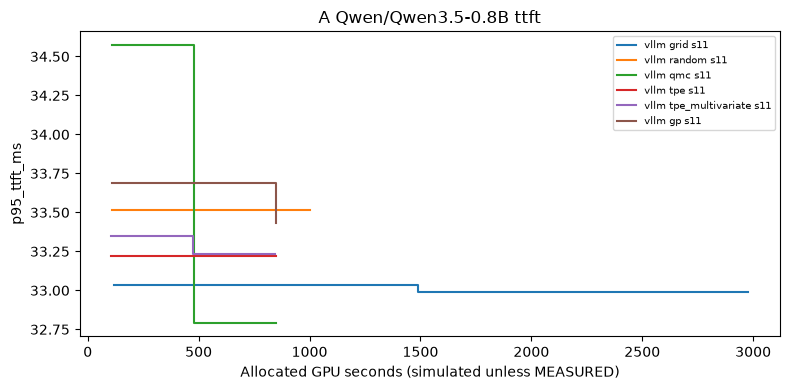

In [14]:
A_single_ttft_studies = run_objective_group(
    "A", "ttft", [c for c in CONCURRENCIES if c == 1]
)
plot_group(A_single_ttft_studies)

### Run A: Pareto E2E + TTFT, concurrency = 1 -- did not run this to save gpu hours, might do it in the future
Both axes are minimized.

In [ ]:
A_single_pareto_latency_studies = run_objective_group(
    "A", "pareto_latency", [c for c in CONCURRENCIES if c == 1]
)
plot_group(A_single_pareto_latency_studies)

### Run A: P95 E2E latency, concurrency > 1
Latency is minimized.

In [ ]:
A_loaded_e2e_studies = run_objective_group(
    "A", "e2e", [c for c in CONCURRENCIES if c > 1]
)
plot_group(A_loaded_e2e_studies)

[I 2026-10-01 18:06:07,487] A new study created in RDB with name: A-sglang-c128-e2e-grid-s11-r1


#Input tokens: 196608
#Output tokens: 49152
A-sglang-c128-e2e-grid-s11-r1: 0 existing trials, 64 remaining


2026-10-01 18:06:08,497 - llm_optimizer.server_utils - INFO - Starting server with command: python3 -m sglang.launch_server --model-path /home/ubuntu/llm-optimizer-trt/models/qwen3.5-0.8b --host 127.0.0.1 --port 30000 --max-running-requests=24 --chunked-prefill-size=2048 --mem-fraction-static=0.75 --schedule-conservativeness=1.0
2026-10-01 18:06:08,498 - llm_optimizer.server_utils - INFO - Waiting for server to be ready at http://127.0.0.1:30000/health...
/home/ubuntu/llm-optimizer-trt/.venv-sglang/lib/python3.12/site-packages/sglang/launch_server.py:71: UserWarning: 'python -m sglang.launch_server' is still supported, but 'sglang serve' is the recommended entrypoint.
  Example: sglang serve --model-path <model> [options]
  warnings.warn(
[2026-10-01 18:06:12] Registered linear attn model: config=GigaChat35Config, backend=GDNAttnBackend, archs=['GigaChat35ForCausalLM', 'GigaChat35ForCausalLMNextN']
[2026-10-01 18:06:21] Attention backend not specified. Use fa3 backend by default.
[2026

  0%|                                                                                                           | 0/384 [00:00<?, ?it/s]

[2026-10-01 18:07:32] Prefill batch, #new-seq: 1, #new-token: 57, #cached-token: 448, full token usage: 0.00, mamba usage: 0.01, #running-req: 0, #queue-req: 122, #pending-token: 0, cuda graph: True, input throughput (token/s): 33.05
[2026-10-01 18:07:32] INFO:     127.0.0.1:60194 - "POST /v1/completions HTTP/1.1" 200 OK
[2026-10-01 18:07:32] Prefill batch, #new-seq: 5, #new-token: 2048, #cached-token: 0, full token usage: 0.00, mamba usage: 0.02, #running-req: 1, #queue-req: 118, #pending-token: 62874, cuda graph: True, input throughput (token/s): 81653.19
[2026-10-01 18:07:32] INFO:     127.0.0.1:60196 - "POST /v1/completions HTTP/1.1" 200 OK
[2026-10-01 18:07:32] INFO:     127.0.0.1:60200 - "POST /v1/completions HTTP/1.1" 200 OK
[2026-10-01 18:07:32] INFO:     127.0.0.1:60202 - "POST /v1/completions HTTP/1.1" 200 OK
[2026-10-01 18:07:32] INFO:     127.0.0.1:60212 - "POST /v1/completions HTTP/1.1" 200 OK
[2026-10-01 18:07:32] Prefill batch, #new-seq: 5, #new-token: 2048, #cached-toke

  0%|▎                                                                                                  | 1/384 [00:01<10:10,  1.59s/it]

... (295 outputs left out)

[2026-10-01 18:14:10] Decode batch, #running-req: 16, #full token: 9103, full token usage: 0.00, mamba num: 64, mamba usage: 0.04, cuda graph: True, gen throughput (token/s): 8475.61, #queue-req: 0
[2026-10-01 18:14:10] Decode batch, #running-req: 16, #full token: 9743, full token usage: 0.00, mamba num: 64, mamba usage: 0.04, cuda graph: True, gen throughput (token/s): 8560.03, #queue-req: 0

============ Serving Benchmark Result ============
Backend:                                 vllm      
Traffic request rate:                    inf       
Max request concurrency:                 128       
Successful requests:                     384       
Benchmark duration (s):                  7.23      
Total input tokens:                      196608    
Total generated tokens:                  49152     
Total generated tokens (retokenized):    49152     
Request throughput (req/s):              53.12     
Input token throughput (tok/s):          27195.18  
Output token throughput (tok/s):

[2026-10-01 18:14:10] SIGTERM received. signum=None frame=None. Draining requests and shutting down...
[2026-10-01 18:14:11] Subprocess scheduler_0 (pid=6050) crashed with exit code -15. Triggering SIGQUIT for cleanup...
[2026-10-01 18:14:11] SIGQUIT received. signum=None, frame=None. It usually means one child failed.
[2026-10-01 18:14:11] Sleeping 5 seconds before crash diagnostics to let GPU activity settle.
[2026-10-01 18:14:16] No live scheduler processes found; skipping py-spy and CUDA coredump.
[2026-10-01 18:14:16] kill_process_tree called: parent_pid=5979, include_parent=True, pid=5979


[I 2026-10-01 18:14:26,981] Trial 5 finished with value: 2491.073990349878 and parameters: {'max_running_requests': 16, 'chunked_prefill_size': 8192, 'mem_fraction_static': 0.8}. Best is trial 1 with value: 1735.2526289999332.


2026-10-01 18:14:27,030 - llm_optimizer.server_utils - INFO - Starting server with command: python3 -m sglang.launch_server --model-path /home/ubuntu/llm-optimizer-trt/models/qwen3.5-0.8b --host 127.0.0.1 --port 30000 --max-running-requests=24 --chunked-prefill-size=6144 --mem-fraction-static=0.85 --schedule-conservativeness=1.0
2026-10-01 18:14:27,031 - llm_optimizer.server_utils - INFO - Waiting for server to be ready at http://127.0.0.1:30000/health...
/home/ubuntu/llm-optimizer-trt/.venv-sglang/lib/python3.12/site-packages/sglang/launch_server.py:71: UserWarning: 'python -m sglang.launch_server' is still supported, but 'sglang serve' is the recommended entrypoint.
  Example: sglang serve --model-path <model> [options]
  warnings.warn(
[2026-10-01 18:14:31] Registered linear attn model: config=GigaChat35Config, backend=GDNAttnBackend, archs=['GigaChat35ForCausalLM', 'GigaChat35ForCausalLMNextN']
[2026-10-01 18:14:36] Attention backend not specified. Use fa3 backend by default.
[2026

### Run A: Throughput, concurrency > 1
Output tokens per second are maximized.

[I 2026-09-29 18:08:31,666] A new study created in RDB with name: A-vllm-c128-throughput-tpe-s11-r1


#Input tokens: 196608
#Output tokens: 49152


2026-09-29 18:08:32,918 - llm_optimizer.server_utils - INFO - Starting server with command: vllm serve /home/ubuntu/llm-optimizer-trt/models/qwen3.5-0.8b --host 127.0.0.1 --port 8000 --max-num-seqs=24 --max-num-batched-tokens=6144 --gpu-memory-utilization=0.85 --enable-chunked-prefill '--compilation-config={"cudagraph_mode": "FULL_AND_PIECEWISE"}'
2026-09-29 18:08:32,919 - llm_optimizer.server_utils - INFO - Waiting for server to be ready at http://127.0.0.1:8000/health...
(APIServer pid=43989) INFO 09-29 18:08:40 [api_utils.py:347] 
(APIServer pid=43989) INFO 09-29 18:08:40 [api_utils.py:347]        █     █     █▄   ▄█
(APIServer pid=43989) INFO 09-29 18:08:40 [api_utils.py:347]  ▄▄ ▄█ █     █     █ ▀▄▀ █  version 0.30.0
(APIServer pid=43989) INFO 09-29 18:08:40 [api_utils.py:347]   █▄█▀ █     █     █     █  model   /home/ubuntu/llm-optimizer-trt/models/qwen3.5-0.8b
(APIServer pid=43989) INFO 09-29 18:08:40 [api_utils.py:347]    ▀▀  ▀▀▀▀▀ ▀▀▀▀▀ ▀     ▀
(APIServer pid=43989) INFO 09-29

  0%|                                                                                                           | 0/384 [00:00<?, ?it/s]

(APIServer pid=43989) INFO:     127.0.0.1:38598 - "POST /v1/completions HTTP/1.1" 200 OK
(APIServer pid=43989) INFO:     127.0.0.1:38604 - "POST /v1/completions HTTP/1.1" 200 OK
(APIServer pid=43989) INFO:     127.0.0.1:38610 - "POST /v1/completions HTTP/1.1" 200 OK
(APIServer pid=43989) INFO:     127.0.0.1:38624 - "POST /v1/completions HTTP/1.1" 200 OK
(APIServer pid=43989) INFO:     127.0.0.1:38626 - "POST /v1/completions HTTP/1.1" 200 OK
(APIServer pid=43989) INFO:     127.0.0.1:38632 - "POST /v1/completions HTTP/1.1" 200 OK
(APIServer pid=43989) INFO:     127.0.0.1:38646 - "POST /v1/completions HTTP/1.1" 200 OK
(APIServer pid=43989) INFO:     127.0.0.1:38662 - "POST /v1/completions HTTP/1.1" 200 OK
(APIServer pid=43989) INFO:     127.0.0.1:38664 - "POST /v1/completions HTTP/1.1" 200 OK
(APIServer pid=43989) INFO:     127.0.0.1:38680 - "POST /v1/completions HTTP/1.1" 200 OK
(APIServer pid=43989) INFO:     127.0.0.1:38694 - "POST /v1/completions HTTP/1.1" 200 OK
(APIServer pid=43989)

  0%|▎                                                                                                  | 1/384 [00:00<03:29,  1.83it/s]

... (2,969 outputs left out)

[I 2026-09-29 20:06:23,651] Trial 29 finished with value: 7527.165530753053 and parameters: {'max_num_seqs': 32, 'max_num_batched_tokens': 6144, 'gpu_memory_utilization': 0.75}. Best is trial 14 with value: 8052.185340345283.


benchmark/completed,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
benchmark/failed,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
benchmark/gpu_seconds,▂█▂▇▄▁▃▄▄█▁▁▄▁▁▁▄▁▂▂▄▁▁▁▁▄▄▇▁▁
benchmark/output_throughput,▆▁▅▁▇▇▄▃▆▁▇▇▆▇█▇▇▇▅▆█████▇▇▂▇▇
benchmark/p95_e2e_latency_ms,▂█▃▇▁▁▃▅▂█▁▁▂▁▁▁▁▂▂▂▁▁▁▁▁▁▁▇▁▁
benchmark/p95_ttft_ms,▂█▂▇▁▁▃▄▂█▁▁▂▁▁▁▁▁▂▂▁▁▁▁▁▁▁▇▁▁
benchmark/total_requests,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
benchmark/wall_seconds,▂█▂▇▄▁▃▄▄█▁▁▄▁▁▁▄▁▂▂▄▁▁▁▁▄▄▇▁▁
best/output_throughput,▁▁▁▁▅▆▆▆▆▆▆▆▆▆████████████████
cost/cumulative_gpu_seconds,▁▁▂▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇███
+7,...


[{'study': 'A-vllm-c128-throughput-tpe-s11-r1',
  'phase': 'A',
  'target_model': 'Qwen/Qwen3.5-0.8B',
  'concurrency': 128,
  'num_prompts': 384,
  'target': 'throughput',
  'directions': ['MAXIMIZE'],
  'attempts': 30,
  'states': {'COMPLETE': 30},
  'unique_configs': 17,
  'allocated_gpu_seconds': 2346.8941862739957,
  'host_search_and_storage_seconds': 1.8382833050018235,
  'best_observed_scalar': 7998.1100026077365,
  'grid_exhausted': None,
  'sampler_semantics': 'tpe'},
 {'study': 'A-vllm-c128-throughput-tpe_multivariate-s11-r1',
  'phase': 'A',
  'target_model': 'Qwen/Qwen3.5-0.8B',
  'concurrency': 128,
  'num_prompts': 384,
  'target': 'throughput',
  'directions': ['MAXIMIZE'],
  'attempts': 30,
  'states': {'COMPLETE': 30},
  'unique_configs': 22,
  'allocated_gpu_seconds': 2368.639156170002,
  'host_search_and_storage_seconds': 2.0804870469983143,
  'best_observed_scalar': 8033.77568104744,
  'grid_exhausted': None,
  'sampler_semantics': 'tpe_multivariate'},
 {'study': 'A

[{'study': 'A-vllm-c128-throughput-tpe-s11-r1',
  'attempted_choice_counts': {'max_num_seqs': {'24': 8,
    '8': 3,
    '32': 16,
    '16': 3},
   'max_num_batched_tokens': {'6144': 8, '2048': 4, '4096': 3, '8192': 15},
   'gpu_memory_utilization': {'0.85': 6, '0.8': 11, '0.9': 2, '0.75': 11}},
  'unvisited_choices': {'max_num_seqs': [],
   'max_num_batched_tokens': [],
   'gpu_memory_utilization': []},
  'note': 'Counts include failures; absent branches are not engine settings'},
 {'study': 'A-vllm-c128-throughput-tpe_multivariate-s11-r1',
  'attempted_choice_counts': {'max_num_seqs': {'24': 8,
    '8': 5,
    '32': 16,
    '16': 1},
   'max_num_batched_tokens': {'6144': 10, '2048': 4, '4096': 5, '8192': 11},
   'gpu_memory_utilization': {'0.85': 5, '0.8': 9, '0.9': 7, '0.75': 9}},
  'unvisited_choices': {'max_num_seqs': [],
   'max_num_batched_tokens': [],
   'gpu_memory_utilization': []},
  'note': 'Counts include failures; absent branches are not engine settings'},
 {'study': 'A-vl

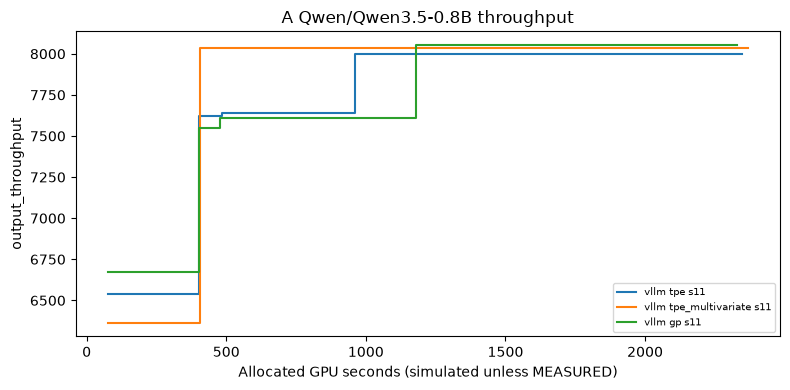

In [11]:
A_loaded_throughput_studies = run_objective_group(
    "A", "throughput", [c for c in CONCURRENCIES if c > 1]
)
plot_group(A_loaded_throughput_studies)

### Run A: Pareto throughput + E2E, concurrency > 1
Throughput is maximized and E2E is minimized.

[I 2026-09-29 20:13:05,782] A new study created in RDB with name: A-vllm-c128-pareto_throughput-tpe-s11-r1


#Input tokens: 196608
#Output tokens: 49152


2026-09-29 20:13:07,152 - llm_optimizer.server_utils - INFO - Starting server with command: vllm serve /home/ubuntu/llm-optimizer-trt/models/qwen3.5-0.8b --host 127.0.0.1 --port 8000 --max-num-seqs=24 --max-num-batched-tokens=6144 --gpu-memory-utilization=0.85 --enable-chunked-prefill '--compilation-config={"cudagraph_mode": "FULL_AND_PIECEWISE"}'
2026-09-29 20:13:07,153 - llm_optimizer.server_utils - INFO - Waiting for server to be ready at http://127.0.0.1:8000/health...
(APIServer pid=81096) INFO 09-29 20:13:15 [api_utils.py:347] 
(APIServer pid=81096) INFO 09-29 20:13:15 [api_utils.py:347]        █     █     █▄   ▄█
(APIServer pid=81096) INFO 09-29 20:13:15 [api_utils.py:347]  ▄▄ ▄█ █     █     █ ▀▄▀ █  version 0.30.0
(APIServer pid=81096) INFO 09-29 20:13:15 [api_utils.py:347]   █▄█▀ █     █     █     █  model   /home/ubuntu/llm-optimizer-trt/models/qwen3.5-0.8b
(APIServer pid=81096) INFO 09-29 20:13:15 [api_utils.py:347]    ▀▀  ▀▀▀▀▀ ▀▀▀▀▀ ▀     ▀
(APIServer pid=81096) INFO 09-29

  0%|                                                                                                           | 0/384 [00:00<?, ?it/s]

(APIServer pid=81096) INFO:     127.0.0.1:53298 - "POST /v1/completions HTTP/1.1" 200 OK
(APIServer pid=81096) INFO:     127.0.0.1:53310 - "POST /v1/completions HTTP/1.1" 200 OK
(APIServer pid=81096) INFO:     127.0.0.1:53320 - "POST /v1/completions HTTP/1.1" 200 OK
(APIServer pid=81096) INFO:     127.0.0.1:53330 - "POST /v1/completions HTTP/1.1" 200 OK
(APIServer pid=81096) INFO:     127.0.0.1:53334 - "POST /v1/completions HTTP/1.1" 200 OK
(APIServer pid=81096) INFO:     127.0.0.1:53350 - "POST /v1/completions HTTP/1.1" 200 OK
(APIServer pid=81096) INFO:     127.0.0.1:53364 - "POST /v1/completions HTTP/1.1" 200 OK
(APIServer pid=81096) INFO:     127.0.0.1:53380 - "POST /v1/completions HTTP/1.1" 200 OK
(APIServer pid=81096) INFO:     127.0.0.1:53392 - "POST /v1/completions HTTP/1.1" 200 OK
(APIServer pid=81096) INFO:     127.0.0.1:53406 - "POST /v1/completions HTTP/1.1" 200 OK
(APIServer pid=81096) INFO:     127.0.0.1:53414 - "POST /v1/completions HTTP/1.1" 200 OK
(APIServer pid=81096)

  0%|▎                                                                                                  | 1/384 [00:00<03:28,  1.83it/s]

... (4,377 outputs left out)

[I 2026-09-29 22:50:19,170] Trial 29 finished with values: [8126.203358462105, 2059.1681713496655] and parameters: {'max_num_seqs': 32, 'max_num_batched_tokens': 8192, 'gpu_memory_utilization': 0.8}.


benchmark/completed,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
benchmark/failed,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
benchmark/gpu_seconds,▂█▂▇▁▁▃▄▁▇▅▃▅▆█▇▃▂▁▁▁▂▂▁▇█▁▆▁▁
benchmark/output_throughput,▆▁▅▂██▄▃▇▁▅▅▃▃▁▂▄▆▇█▇▅▅▇▁▁▇▂██
benchmark/p95_e2e_latency_ms,▂█▂▇▁▁▃▄▁▇▃▃▅▄█▆▃▂▂▁▁▂▂▁▇█▁▆▁▁
benchmark/p95_ttft_ms,▂█▂▇▁▁▃▄▁▇▃▂▄▄█▇▃▂▂▁▁▂▂▁▇█▁▆▁▁
benchmark/total_requests,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
benchmark/wall_seconds,▂█▂▇▁▁▃▄▁▇▅▃▅▆█▇▃▂▁▁▁▂▂▁▇█▁▆▁▁
cost/cumulative_gpu_seconds,▁▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇███
objective/output_throughput,▆▁▅▂██▄▃▇▁▅▅▃▃▁▂▄▆▇█▇▅▅▇▁▁▇▂██
+7,...


[{'study': 'A-vllm-c128-pareto_throughput-tpe-s11-r1',
  'phase': 'A',
  'target_model': 'Qwen/Qwen3.5-0.8B',
  'concurrency': 128,
  'num_prompts': 384,
  'target': 'pareto_throughput',
  'directions': ['MAXIMIZE', 'MINIMIZE'],
  'attempts': 30,
  'states': {'COMPLETE': 30},
  'unique_configs': 18,
  'allocated_gpu_seconds': 2312.0978375230043,
  'host_search_and_storage_seconds': 1.996661207989746,
  'best_observed_scalar': None,
  'grid_exhausted': None,
  'sampler_semantics': 'tpe'},
 {'study': 'A-vllm-c128-pareto_throughput-tpe_multivariate-s11-r1',
  'phase': 'A',
  'target_model': 'Qwen/Qwen3.5-0.8B',
  'concurrency': 128,
  'num_prompts': 384,
  'target': 'pareto_throughput',
  'directions': ['MAXIMIZE', 'MINIMIZE'],
  'attempts': 30,
  'states': {'COMPLETE': 30},
  'unique_configs': 24,
  'allocated_gpu_seconds': 2366.258899918019,
  'host_search_and_storage_seconds': 1.8127220129972557,
  'best_observed_scalar': None,
  'grid_exhausted': None,
  'sampler_semantics': 'tpe_mult

[{'study': 'A-vllm-c128-pareto_throughput-tpe-s11-r1',
  'attempted_choice_counts': {'max_num_seqs': {'24': 9,
    '8': 3,
    '32': 14,
    '16': 4},
   'max_num_batched_tokens': {'6144': 8, '2048': 4, '4096': 4, '8192': 14},
   'gpu_memory_utilization': {'0.85': 5, '0.8': 8, '0.9': 3, '0.75': 14}},
  'unvisited_choices': {'max_num_seqs': [],
   'max_num_batched_tokens': [],
   'gpu_memory_utilization': []},
  'note': 'Counts include failures; absent branches are not engine settings'},
 {'study': 'A-vllm-c128-pareto_throughput-tpe_multivariate-s11-r1',
  'attempted_choice_counts': {'max_num_seqs': {'24': 8,
    '8': 6,
    '32': 13,
    '16': 3},
   'max_num_batched_tokens': {'6144': 5, '2048': 5, '4096': 5, '8192': 15},
   'gpu_memory_utilization': {'0.85': 6, '0.8': 13, '0.9': 5, '0.75': 6}},
  'unvisited_choices': {'max_num_seqs': [],
   'max_num_batched_tokens': [],
   'gpu_memory_utilization': []},
  'note': 'Counts include failures; absent branches are not engine settings'},
 {'

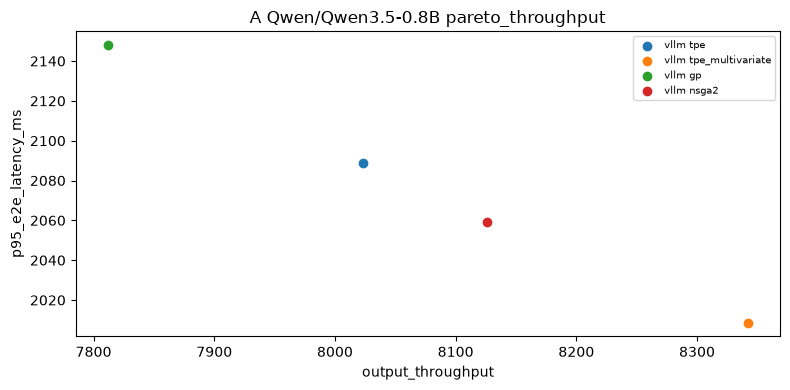

In [12]:
A_loaded_pareto_throughput_studies = run_objective_group(
    "A", "pareto_throughput", [c for c in CONCURRENCIES if c > 1]
)
plot_group(A_loaded_pareto_throughput_studies)

## Phase B: expanded search on Qwen3.5-4B
The following six running cells are independent objective tasks. Run only the cells you want after setup. All scalar cells include the six sampler arms; Pareto adds NSGA-II and uses no intermediate pruning. Model, request count, concurrency and objective are explicit in every study contract/name. Phase B capped Grid is not exhaustive. Re-running a cell creates newly labeled studies rather than silently resuming incompatible state.


### Run B: P95 E2E latency, concurrency = 1
Latency is minimized.

In [ ]:
B_single_e2e_studies = run_objective_group(
    "B", "e2e", [c for c in CONCURRENCIES if c == 1]
)
plot_group(B_single_e2e_studies)

### Run B: P95 TTFT, concurrency = 1
Latency is minimized.

In [ ]:
B_single_ttft_studies = run_objective_group(
    "B", "ttft", [c for c in CONCURRENCIES if c == 1]
)
plot_group(B_single_ttft_studies)

### Run B: Pareto E2E + TTFT, concurrency = 1
Both axes are minimized.

In [ ]:
B_single_pareto_latency_studies = run_objective_group(
    "B", "pareto_latency", [c for c in CONCURRENCIES if c == 1]
)
plot_group(B_single_pareto_latency_studies)

### Run B: P95 E2E latency, concurrency > 1
Latency is minimized.

In [26]:
# !python -c "import vllm; print(vllm.__version__)"

# !vllm serve --help=all | grep -A 5 -E \
# 'max-num-partial-prefills|enable-chunked-prefill'

0.30.0
  --enable-chunked-prefill, --no-enable-chunked-prefill
                        If True, prefill requests can be chunked based on the
                        remaining `max_num_batched_tokens`.
                        The default value here is mainly for convenience when
                        testing. In real usage, this should be set in
                        `EngineArgs.create_engine_config`. (default: None)


In [ ]:
B_loaded_e2e_studies = run_objective_group(
    "B", "e2e", [c for c in CONCURRENCIES if c > 1]
)
plot_group(B_loaded_e2e_studies)

[I 2026-10-03 18:55:53,212] A new study created in RDB with name: B-sglang-c128-e2e-tpe-s11-r8


#Input tokens: 458752
#Output tokens: 114688
B-sglang-c128-e2e-tpe-s11-r8: 1 existing trials, 19 remaining


SGLang config diagnostic: {'disable_cuda_graph_source': 'absent', 'disable_cuda_graph_value': '<absent>', 'fixed_server': {}, 'sampled_config': {'max_running_requests': 24, 'chunked_prefill_size': 6144, 'mem_fraction_static': 0.8, 'cuda_graph_backend_decode': 'disabled', 'cuda_graph_backend_prefill': 'disabled', 'schedule_conservativeness': 0.75, 'attention_backend': 'flashinfer', 'disable_radix_cache': False, 'schedule_policy': 'shortest-prefill-first', 'enable_mixed_chunk': False, 'disable_overlap_schedule': False, 'max_prefill_tokens': 8192}, 'merged_config': {'max_running_requests': 24, 'chunked_prefill_size': 6144, 'mem_fraction_static': 0.8, 'cuda_graph_backend_decode': 'disabled', 'cuda_graph_backend_prefill': 'disabled', 'schedule_conservativeness': 0.75, 'attention_backend': 'flashinfer', 'disable_radix_cache': False, 'schedule_policy': 'shortest-prefill-first', 'enable_mixed_chunk': False, 'disable_overlap_schedule': False, 'max_prefill_tokens': 8192}}
2026-10-03 18:55:54,329

  0%|                                                                                                           | 0/896 [00:00<?, ?it/s]

[2026-10-03 18:56:49] Prefill batch, #new-seq: 1, #new-token: 57, #cached-token: 448, full token usage: 0.01, mamba usage: 0.08, #running-req: 0, #queue-req: 26, #pending-token: 0, cuda graph: False, input throughput (token/s): 27.80
[2026-10-03 18:56:49] INFO:     127.0.0.1:53372 - "POST /v1/completions HTTP/1.1" 200 OK
[2026-10-03 18:56:49] Prefill batch, #new-seq: 13, #new-token: 6144, #cached-token: 0, full token usage: 0.01, mamba usage: 0.15, #running-req: 1, #queue-req: 100, #pending-token: 13810, cuda graph: False, input throughput (token/s): 75597.37
[2026-10-03 18:56:49] INFO:     127.0.0.1:53448 - "POST /v1/completions HTTP/1.1" 200 OK
[2026-10-03 18:56:49] INFO:     127.0.0.1:53706 - "POST /v1/completions HTTP/1.1" 200 OK
[2026-10-03 18:56:49] INFO:     127.0.0.1:53556 - "POST /v1/completions HTTP/1.1" 200 OK
[2026-10-03 18:56:49] INFO:     127.0.0.1:53388 - "POST /v1/completions HTTP/1.1" 200 OK
[2026-10-03 18:56:49] INFO:     127.0.0.1:53444 - "POST /v1/completions HTTP/1

  0%|                                                                                                   | 1/896 [00:03<54:40,  3.67s/it]

... (378 outputs left out)

 67%|█████████████████████████████████████████████████████████████████                                | 601/896 [00:57<00:26, 11.10it/s]

[2026-10-03 19:05:47] Decode batch, #running-req: 8, #full token: 5017, full token usage: 0.00, mamba num: 8, mamba usage: 1.00, cuda graph: True, gen throughput (token/s): 1525.42, #queue-req: 120
[2026-10-03 19:05:47] Prefill batch, #new-seq: 8, #new-token: 4041, #cached-token: 0, full token usage: 0.00, mamba usage: 1.00, #running-req: 0, #queue-req: 112, #pending-token: 57271, cuda graph: False, input throughput (token/s): 5599.57
[2026-10-03 19:05:47] INFO:     127.0.0.1:57724 - "POST /v1/completions HTTP/1.1" 200 OK
[2026-10-03 19:05:47] INFO:     127.0.0.1:57736 - "POST /v1/completions HTTP/1.1" 200 OK
[2026-10-03 19:05:47] INFO:     127.0.0.1:57742 - "POST /v1/completions HTTP/1.1" 200 OK
[2026-10-03 19:05:47] INFO:     127.0.0.1:57746 - "POST /v1/completions HTTP/1.1" 200 OK
[2026-10-03 19:05:47] INFO:     127.0.0.1:57762 - "POST /v1/completions HTTP/1.1" 200 OK
[2026-10-03 19:05:47] INFO:     127.0.0.1:57764 - "POST /v1/completions HTTP/1.1" 200 OK
[2026-10-03 19:05:47] INFO:

 68%|█████████████████████████████████████████████████████████████████▉                               | 609/896 [00:58<00:25, 11.09it/s]

[2026-10-03 19:05:48] Decode batch, #running-req: 8, #full token: 4921, full token usage: 0.00, mamba num: 8, mamba usage: 1.00, cuda graph: True, gen throughput (token/s): 1531.88, #queue-req: 120
[2026-10-03 19:05:48] Prefill batch, #new-seq: 8, #new-token: 4095, #cached-token: 0, full token usage: 0.00, mamba usage: 1.00, #running-req: 0, #queue-req: 112, #pending-token: 57271, cuda graph: False, input throughput (token/s): 5672.46
[2026-10-03 19:05:48] INFO:     127.0.0.1:57780 - "POST /v1/completions HTTP/1.1" 200 OK
[2026-10-03 19:05:48] INFO:     127.0.0.1:57784 - "POST /v1/completions HTTP/1.1" 200 OK
[2026-10-03 19:05:48] INFO:     127.0.0.1:57788 - "POST /v1/completions HTTP/1.1" 200 OK
[2026-10-03 19:05:48] INFO:     127.0.0.1:57800 - "POST /v1/completions HTTP/1.1" 200 OK
[2026-10-03 19:05:48] INFO:     127.0.0.1:57802 - "POST /v1/completions HTTP/1.1" 200 OK
[2026-10-03 19:05:48] INFO:     127.0.0.1:57806 - "POST /v1/completions HTTP/1.1" 200 OK
[2026-10-03 19:05:48] INFO:

### Run B: Throughput, concurrency > 1
Output tokens per second are maximized.

In [ ]:
B_loaded_throughput_studies = run_objective_group(
    "B", "throughput", [c for c in CONCURRENCIES if c > 1]
)
plot_group(B_loaded_throughput_studies)

### Run B: Pareto throughput + E2E, concurrency > 1
Throughput is maximized and E2E is minimized.

In [ ]:
B_loaded_pareto_throughput_studies = run_objective_group(
    "B", "pareto_throughput", [c for c in CONCURRENCIES if c > 1]
)
plot_group(B_loaded_pareto_throughput_studies)

### Optional constraint-aware scalar and Pareto searches
Keep disabled for the main objective comparisons. Enable to optimize the same objectives subject to illustrative TTFT/E2E SLOs and zero failed requests, using constraint-aware TPE (or a supported GP/NSGA-II arm). These are separate tasks, use no intermediate pruning, and independent validation requires feasibility for all repeats. They are not weighted penalties.


In [ ]:
RUN_CONSTRAINED_DEMO = False


def run_constrained_objectives(phase="B", sampler_name="tpe_multivariate"):
    # Use a constraint-aware sampler; arbitrary scalar penalties are not applied.
    GROUP_RUNS[("constrained", phase)] += 1
    results = {}
    for c in CONCURRENCIES:
        for framework in REAL_FRAMEWORKS if RUN_REAL_GPU else FRAMEWORKS:
            for target in objectives_for(c):
                label = (
                    f"constrained-{phase}-{framework}-c{c}-{target}"
                    f"-r{GROUP_RUNS[('constrained', phase)]}"
                )
                benchmark = benchmark_for(phase, framework, c, label)
                choices = (
                    REAL_PREFLIGHT[(phase, framework)].get("expanded_choices")
                    if RUN_REAL_GPU and phase == "B"
                    else None
                )
                study = run_study(
                    label,
                    framework,
                    sampler_name,
                    concurrency=c,
                    phase=phase,
                    target=target,
                    constrained=True,
                    benchmark=benchmark,
                    choices=choices,
                    space_kind="baseline" if phase == "A" else "expanded",
                )
                results[(phase, c, framework, target, "constrained")] = study
    CONSTRAINED_STUDIES.update(results)
    display([summarize(s) for s in results.values()])
    return results


if RUN_CONSTRAINED_DEMO:
    run_constrained_objectives("B")
else:
    print("Constrained searches disabled; main objective cells are unconstrained.")

## 8. Calibrate pruning independently for every scalar task
Calibration keys include phase/model, framework, concurrency and objective. Use full, comparable benchmark trajectories to check 25%/50%-versus-final ranking and replay false-pruning among eventual best configurations. Do not carry Phase A calibration into Phase B, or use TTFT calibration for E2E. Pilot request counts can make tail statistics unstable.

These examples calibrate the CPU simulator. A real adapter must stream one continuous, post-warmup workload and terminate requests/server immediately on cancellation. `RepositoryBenchmark` has no checkpoints, so real pruning is explicitly skipped, never emulated with restarted engines or reduced concurrency. Pareto studies are deliberately absent from this section.


In [ ]:
def scalar_tasks():
    return [
        (phase, c, fw, target)
        for phase in PHASE_MODELS
        for c in CONCURRENCIES
        for fw in (REAL_FRAMEWORKS if RUN_REAL_GPU else FRAMEWORKS)
        for target in objectives_for(c)
        if not target.startswith("pareto")
    ]


def calibrate_pruning(phase, concurrency, framework, target, samples=32):
    target, metrics, directions = objective_spec(target, concurrency)
    if len(metrics) != 1:
        raise ValueError("Pareto pruning is unsupported")
    pilot = optuna.create_study(sampler=optuna.samplers.RandomSampler(seed=73))
    benchmark = Simulator(seed=9001, phase=phase)
    trajectories = []
    for _ in range(samples):
        trial = pilot.ask()
        cfg = suggest_config(
            trial, framework, concurrency, "baseline" if phase == "A" else "expanded"
        )
        try:
            rows = list(benchmark.stream(framework, cfg, concurrency))
        except BenchmarkFailure:
            pilot.tell(trial, state=TrialState.FAIL)
            continue
        scores = [getattr(row[2], metrics[0]) for row in rows]
        pilot.tell(trial, scores[-1])
        trajectories.append({"scores": scores, "costs": [row[3] for row in rows]})
    if len(trajectories) < 3:
        raise ValueError("Insufficient valid calibration trajectories")
    scores = np.array([r["scores"] for r in trajectories])
    minimizing = directions[0] == "minimize"
    order = np.argsort(scores[:, -1])
    top_count = max(1, math.ceil(len(scores) * 0.1))
    top = set(order[:top_count] if minimizing else order[-top_count:])
    history, stopped = [], set()
    for i in np.random.default_rng(73).permutation(len(scores)):
        worse = len(history) >= 8 and (
            scores[i, 0] > np.median(history)
            if minimizing
            else scores[i, 0] < np.median(history)
        )
        if worse:
            stopped.add(i)
        else:
            history.append(scores[i, 0])
    total = sum(sum(r["costs"]) for r in trajectories)
    replay = sum(
        r["costs"][0] if i in stopped else sum(r["costs"])
        for i, r in enumerate(trajectories)
    )
    correlations = [
        float(spearmanr(scores[:, step], scores[:, -1]).statistic) for step in [0, 1]
    ]
    return {
        "phase": phase,
        "model": PHASE_MODELS[phase],
        "framework": framework,
        "concurrency": concurrency,
        "target": target,
        "metric": metrics[0],
        "direction": directions[0],
        "workload": workload_for(concurrency, phase),
        "valid_trajectories": len(scores),
        "rank_correlations": [v if np.isfinite(v) else None for v in correlations],
        "false_prune_rate_among_top_10pct": len(top & stopped) / len(top),
        "replayed_time_saved_fraction": 1 - replay / total,
        "threshold": float(np.percentile(scores[:, 0], 90 if minimizing else 10)),
    }


calibration = {}
if not RUN_REAL_GPU:
    for phase, c, fw, target in scalar_tasks():
        calibration[(phase, c, fw, target)] = calibrate_pruning(
            phase, c, fw, target, samples=12 if QUICK_DEMO else 64
        )
    display(list(calibration.values()))
else:
    print(
        "Real calibration skipped: RepositoryBenchmark has no continuous checkpoints."
    )

## 9. Objective-specific scalar pruning comparisons
E2E and TTFT are minimized: percentile pruning uses 75 and threshold pruning uses an upper bound. Throughput is maximized: percentile pruning uses 25 and threshold pruning uses a lower bound. Thresholds come from that exact task's calibration, not a TTFT constant reused for E2E. Pruning reports the task's selected metric at common steps; request budget is a fraction of the same phase-specific full budget.

Nop, Median, Percentile, Successive Halving, Hyperband and Threshold are compared with the same sampler and workload for each scalar task. Validate survivors independently. There is no native Pareto `report()`/`should_prune()` arm.


In [ ]:
def pruner_menu(direction, threshold):
    minimizing = str(direction).lower() == "minimize"
    return {
        "nop": (optuna.pruners.NopPruner, {}),
        "median": (
            optuna.pruners.MedianPruner,
            {"n_startup_trials": 4, "n_warmup_steps": 1, "n_min_trials": 3},
        ),
        "percentile": (
            optuna.pruners.PercentilePruner,
            {
                "percentile": 75 if minimizing else 25,
                "n_startup_trials": 4,
                "n_warmup_steps": 1,
                "n_min_trials": 3,
            },
        ),
        "halving": (
            optuna.pruners.SuccessiveHalvingPruner,
            {"min_resource": 1, "reduction_factor": 2},
        ),
        "hyperband": (
            optuna.pruners.HyperbandPruner,
            {"min_resource": 1, "max_resource": 3, "reduction_factor": 2},
        ),
        "threshold": (
            optuna.pruners.ThresholdPruner,
            {("upper" if minimizing else "lower"): threshold, "n_warmup_steps": 1},
        ),
    }


def run_pruning_objective(target):
    results = {}
    if RUN_REAL_GPU:
        print(f"{target}: real pruning skipped; no continuous checkpoint adapter.")
        return results
    GROUP_RUNS[("pruning", target)] += 1
    for phase, c, fw, task_target in scalar_tasks():
        if task_target != target:
            continue
        if (phase, c, fw, target) not in calibration:
            raise ValueError(
                "Calibrate this phase/concurrency/objective before pruning"
            )
        cal = calibration[(phase, c, fw, target)]
        if cal["workload"] != workload_for(c, phase):
            raise ValueError("Workload changed after calibration; recalibrate first")
        for name, (pruner_type, settings) in pruner_menu(
            cal["direction"], cal["threshold"]
        ).items():
            key = (phase, c, fw, target, name)
            study = run_study(
                f"pruning-{phase}-{fw}-c{c}-{target}-{name}"
                f"-r{GROUP_RUNS[('pruning', target)]}",
                fw,
                concurrency=c,
                phase=phase,
                target=target,
                space_kind="baseline" if phase == "A" else "expanded",
                pruner=pruner_type(**settings),
                pruner_settings=settings,
                trials=12 if QUICK_DEMO else 32,
            )
            results[key] = study
    display([summarize(s) for s in results.values()])
    return results

### Run pruning: e2e
Separate scalar pruning cell; both phases and all applicable concurrency/framework tasks retain their own calibration.

In [ ]:
e2e_pruning_studies = run_pruning_objective("e2e")

### Run pruning: ttft
Separate scalar pruning cell; both phases and all applicable concurrency/framework tasks retain their own calibration.

In [ ]:
ttft_pruning_studies = run_pruning_objective("ttft")

### Run pruning: throughput
Separate scalar pruning cell; both phases and all applicable concurrency/framework tasks retain their own calibration.

In [ ]:
throughput_pruning_studies = run_pruning_objective("throughput")

## 10. Independent validation per objective and task
Shortlist scalar candidates by their actual direction; shortlist Pareto candidates using the actual direction vector. Recommendations are keyed by phase/model, framework, concurrency, objective, workload and measured/synthetic environment. Never pool E2E and TTFT studies into one latency winner, or use a throughput winner to represent the latency objective.

Default validation uses five independent 1000-request repeats per phase, with reserved request seeds (not optimizer sampling seeds). Every candidate in a task sees the same holdout request seeds/counts. Records include separate E2E, TTFT and throughput replicate distributions, mean-of-run-P95 uncertainty, failures, and allocation cost. These are not confidence intervals for the pooled request-level percentile. Failed repeats cannot improve selection.

Scalar recommendations use the matching repeated metric; Pareto recommendations retain the independently validated non-dominated set without a scalarized winner. SLO feasibility is logged separately; set `VALIDATION_REQUIRE_SLO=True` if selecting deployment-feasible candidates rather than unconstrained objective optima. No recommendation is issued when no candidate passes the chosen gate. Real validation automatically uses the real adapter, never the simulator.


In [ ]:
VALIDATION_REQUIRE_SLO = False


def task_identity(contract):
    # Objective identity and frozen search workload are part of the validation task.
    payload = {
        k: contract[k]
        for k in [
            "phase",
            "target_model",
            "framework",
            "concurrency",
            "target",
            "metrics",
            "directions",
            "workload",
            "environment",
            "constrained",
            "ttft_limit_ms",
            "e2e_limit_ms",
        ]
    }
    return hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()[:16]


def shortlist(studies, k=3):
    candidates = {}
    for study in studies:
        contract = study.user_attrs["contract"]
        task_id = task_identity(contract)
        valid = completed(study, feasible_only=contract["constrained"])
        if len(study.directions) > 1:
            selected = pareto_front(valid, study.directions)
        else:
            selected = sorted(
                valid,
                key=lambda t: t.value,
                reverse=study.directions[0].name == "MAXIMIZE",
            )[:k]
        for trial in selected:
            cfg = trial.user_attrs["config"]
            cfg_id = config_fingerprint(
                contract["framework"], contract["concurrency"], cfg, contract["phase"]
            )
            key = task_id + ":" + cfg_id
            candidates[key] = {
                "task_id": task_id,
                "config_id": cfg_id,
                "config": cfg,
                "contract": contract,
            }
    return candidates


def repeat_summary(values):
    values = np.asarray(values, dtype=float)
    if len(values) == 0:
        return {
            "mean": None,
            "median": None,
            "sd": None,
            "mean_95pct_t_interval": None,
            "replicates": [],
        }
    mean = float(values.mean())
    sd = float(values.std(ddof=1)) if len(values) > 1 else None
    half = (
        float(student_t.ppf(0.975, len(values) - 1) * sd / np.sqrt(len(values)))
        if sd is not None
        else None
    )
    return {
        "mean": mean,
        "median": float(np.median(values)),
        "sd": sd,
        "mean_95pct_t_interval": [mean - half, mean + half]
        if half is not None
        else None,
        "replicates": values.tolist(),
    }


def validate_candidates(candidates, repeats=None, benchmark_factory=None):
    repeats = VALIDATION_REPEATS if repeats is None else repeats
    if not isinstance(repeats, int) or repeats < 1:
        raise ValueError("Validation repeats must be positive")
    rows = []
    for key, candidate in candidates.items():
        contract = candidate["contract"]
        phase, fw, c = contract["phase"], contract["framework"], contract["concurrency"]
        count = VALIDATION_REQUESTS[phase]
        measurements, failures, spent = [], [], 0.0
        for repeat in range(repeats):
            label = f"validation-{key.replace(':', '-')}-repeat{repeat}"
            seed = 50000 + repeat
            benchmark = (
                benchmark_factory(fw, c, repeat, phase, count, seed)
                if benchmark_factory
                else benchmark_for(
                    phase,
                    fw,
                    c,
                    label,
                    num_prompts=count,
                    workload_seed=seed,
                    repeat=repeat,
                )
            )
            if hasattr(benchmark, "phase") and benchmark.phase != phase:
                raise ValueError("Validation adapter and candidate phase/model differ")
            source = contract["environment"].get("measurement", "SYNTHETIC")
            if (
                source == "MEASURED"
                and getattr(benchmark, "environment", {}).get("measurement")
                != "MEASURED"
            ):
                raise ValueError(
                    "Measured candidates cannot be validated synthetically"
                )
            if source == "MEASURED":
                for field in [
                    "framework_version",
                    "cuda_version",
                    "driver_version",
                    "model_revision",
                    "model",
                    "gpu_type",
                    "gpu_count",
                ]:
                    if benchmark.environment.get(field) != contract["environment"].get(
                        field
                    ):
                        raise ValueError(f"Validation environment changed: {field}")
            try:
                m = validate_measurement(benchmark.measure(fw, candidate["config"], c))
                if m.total_requests != count:
                    raise measurement_failure("Validation request count changed", m)
                measurements.append(m)
                spent += m.gpu_seconds
            except BenchmarkFailure as exc:
                failures.append(
                    {
                        "repeat": repeat,
                        "reason": str(exc),
                        "request_accounting": getattr(exc, "request_accounting", {}),
                    }
                )
                spent += getattr(exc, "gpu_seconds", 12.0)
        stats = {
            metric: repeat_summary([getattr(m, metric) for m in measurements])
            for metric in ["output_throughput", "p95_ttft_ms", "p95_e2e_latency_ms"]
        }
        complete = len(measurements) == repeats
        feasible = complete and all(
            m.p95_ttft_ms <= contract["ttft_limit_ms"]
            and m.p95_e2e_latency_ms <= contract["e2e_limit_ms"]
            for m in measurements
        )
        rows.append(
            {
                "candidate_key": key,
                "task_id": candidate["task_id"],
                "config_id": candidate["config_id"],
                "phase": phase,
                "target_model": PHASE_MODELS[phase],
                "framework": fw,
                "concurrency": c,
                "target": contract["target"],
                "metrics": contract["metrics"],
                "directions": contract["directions"],
                "constrained": contract["constrained"],
                "config": candidate["config"],
                "attempts": repeats,
                "num_prompts_per_repeat": count,
                "successful_repeats": len(measurements),
                "failures": failures,
                "gpu_seconds": spent,
                "statistics": stats,
                "validation_complete": complete,
                "validation_feasible": feasible,
                "validated_values": [
                    stats[metric]["mean"] for metric in contract["metrics"]
                ],
                "measurement_source": measurements[0].source if measurements else None,
            }
        )
    return rows


def validation_recommendations(rows, require_slo=False):
    recommendations = {}
    for task_id in sorted({row["task_id"] for row in rows}):
        eligible = [
            row
            for row in rows
            if row["task_id"] == task_id
            and row["validation_complete"]
            and (not (require_slo or row["constrained"]) or row["validation_feasible"])
        ]
        if not eligible:
            recommendations[task_id] = None
            continue
        directions = eligible[0]["directions"]
        if len(directions) > 1:
            recommendations[task_id] = [
                row
                for row in eligible
                if not any(
                    dominates(
                        other["validated_values"], row["validated_values"], directions
                    )
                    for other in eligible
                )
            ]
        else:
            recommendations[task_id] = (min if directions[0] == "MINIMIZE" else max)(
                eligible, key=lambda row: row["validated_values"][0]
            )
    return recommendations


PRUNING_STUDIES = {
    **e2e_pruning_studies,
    **ttft_pruning_studies,
    **throughput_pruning_studies,
}
all_studies = [
    *STUDIES.values(),
    *CONSTRAINED_STUDIES.values(),
    *PRUNING_STUDIES.values(),
]
validation_rows = validate_candidates(shortlist(all_studies))
recommendations = validation_recommendations(validation_rows, VALIDATION_REQUIRE_SLO)
display(recommendations)
print("CPU recommendations are synthetic; no deployment performance is established.")

## 11. Durable artifacts and cost reporting
Persist contracts, exact objective vectors/distributions, failure accounting, calibration and independent repeats. SQLite studies and JSON are under the displayed `RUN_DIR`. Trial counts include repetitions and failed/pruned attempts; allocation time includes startup and unsuccessful runs. Validation cost is additional. Grid's best is only an observed finite-grid reference, especially when Phase B is capped.


In [ ]:
artifact = {
    "controls": {
        "models": PHASE_MODELS,
        "concurrencies": CONCURRENCIES,
        "phase_requests": PHASE_REQUESTS,
        "validation_requests": VALIDATION_REQUESTS,
        "quick_demo": QUICK_DEMO,
    },
    "skipped_arms": SKIPPED_ARMS,
    "calibration": list(calibration.values()),
    "studies": [
        {
            "name": s.study_name,
            "contract": s.user_attrs["contract"],
            "summary": summarize(s),
            "trials": [
                {
                    "number": t.number,
                    "state": t.state.name,
                    "values": t.values,
                    "params": t.params,
                    "distributions": {
                        k: json.loads(optuna.distributions.distribution_to_json(v))
                        for k, v in t.distributions.items()
                    },
                    "attrs": t.user_attrs,
                    "intermediate_values": t.intermediate_values,
                }
                for t in s.trials
            ],
        }
        for s in all_studies
    ],
    "validation": validation_rows,
    "recommendations": recommendations,
}


def artifact_value(value):
    if isinstance(value, dict):
        return {k: artifact_value(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [artifact_value(v) for v in value]
    if isinstance(value, float) and math.isinf(value):
        return "inf" if value > 0 else "-inf"
    return value


(RUN_DIR / "results.json").write_text(
    json.dumps(artifact_value(artifact), indent=2, allow_nan=False)
)
if all_studies:
    reloaded = optuna.load_study(study_name=all_studies[0].study_name, storage=STORAGE)
    assert len(reloaded.trials) == len(all_studies[0].trials)
print("Artifacts:", RUN_DIR)

## 12. Correctness checks and implementation boundaries
Directions, objective-specific measurements, request counts and Pareto dominance are invariants—not a requirement that one noisy sampler beats another. CPU tests mock real adapter argument forwarding and cleanup; they do not validate hardware support. Real latency excludes client admission waiting, and real intermediate pruning still needs a checkpoint adapter.


In [ ]:
for study in all_studies:
    contract = study.user_attrs["contract"]
    _, metrics, directions = objective_spec(contract["target"], contract["concurrency"])
    assert contract["metrics"] == metrics
    assert [d.name for d in study.directions] == [d.upper() for d in directions]
    for trial in completed(study):
        measurement = trial.user_attrs["measurement"]
        assert list(trial.values) == [measurement[metric] for metric in metrics]
        assert measurement["total_requests"] == contract["workload"]["num_prompts"]
        assert measurement["failed"] == 0
    if len(metrics) > 1:
        assert not any(t.state == TrialState.PRUNED for t in study.trials)
        assert {t.number for t in pareto_front(completed(study), study.directions)} == {
            t.number for t in study.best_trials
        }
for row in validation_rows:
    assert row["num_prompts_per_repeat"] == VALIDATION_REQUESTS[row["phase"]]
    assert row["successful_repeats"] + len(row["failures"]) == row["attempts"]
assert (RUN_DIR / "results.json").exists()
print("Correctness checks passed; real GPU execution:", RUN_REAL_GPU)

## References and implementation boundaries
The code examples use the Optuna **4.9.0** API rather than assuming that changing stable documentation matches the installed environment.

- [Experiment plan](../../optuna_experiments.md) and [repository audit](../optuna_benchmark_audit.md).
- [Optuna 4.9 TPE: startup, multivariate/group, constraint semantics](https://optuna.readthedocs.io/en/v4.9.0/reference/samplers/generated/optuna.samplers.TPESampler.html).
- [Optuna 4.9 Trial: reporting and multiobjective limitations](https://optuna.readthedocs.io/en/v4.9.0/reference/generated/optuna.trial.Trial.html).
- [Optuna 4.9 QMC: numerical distributions and categorical fallback](https://optuna.readthedocs.io/en/v4.9.0/reference/samplers/generated/optuna.samplers.QMCSampler.html).
- [Optuna 4.9 GP](https://optuna.readthedocs.io/en/v4.9.0/reference/samplers/generated/optuna.samplers.GPSampler.html) and [pruners](https://optuna.readthedocs.io/en/v4.9.0/reference/pruners.html).
- [OptunaHub sampler catalog](https://hub.optuna.org/samplers/) and [MultiMetricPruner](https://hub.optuna.org/pruners/multi_metric_pruner/).

The GPU adapter is an integration example using the inspected repository functions; it has not been validated on GPU hardware by running this notebook. Its CPU demonstrations explain the optimization workflow, not real throughput or SLO attainability.

- [vLLM native CUDA graph modes](https://docs.vllm.ai/en/latest/design/cuda_graphs/).
- [TensorRT-LLM nested graph/KV YAML settings](https://nvidia.github.io/TensorRT-LLM/commands/trtllm-serve/run-benchmark-with-trtllm-serve.html).
- [SGLang native graph flags and version caveats](https://docs.sglang.io/docs/advanced_features/server_arguments).

- [Qwen3.5-0.8B model card](https://huggingface.co/Qwen/Qwen3.5-0.8B) and [Qwen3.5-4B model card](https://huggingface.co/Qwen/Qwen3.5-4B).
- [vLLM native engine arguments](https://docs.vllm.ai/en/latest/configuration/engine_args/).
- [SGLang native server arguments](https://docs.sglang.io/docs/advanced_features/server_arguments).
- [TRT TorchLlmArgs](https://nvidia.github.io/TensorRT-LLM/llm-api/reference/TorchLlmArgs.html) and [scheduler policies](https://nvidia.github.io/TensorRT-LLM/llm-api/reference/SchedulerConfig.html).

- [Optuna GP: multiobjective acquisition and independent conditional sampling](https://optuna.readthedocs.io/en/v4.9.0/reference/samplers/generated/optuna.samplers.GPSampler.html).
- [Optuna QMC: fixed numerical space and independent categorical sampling](https://optuna.readthedocs.io/en/v4.9.0/reference/samplers/generated/optuna.samplers.QMCSampler.html).

The lazy GridSampler is pinned to the tested Optuna 4.9 internals. The native benchmark client already exports `p95_e2e_latency_ms`; this notebook uses that measured field directly.

- [W&B run logging and summaries](https://docs.wandb.ai/models/ref/python/experiments/run) and [initialization/offline mode](https://docs.wandb.ai/models/ref/python/functions/init).


GP failed-configuration policy: effective configurations are canonicalized with model and fixed settings. Previously failed fingerprints are rejected before server launch. After 10 consecutive blocked proposals, the study stops with a diagnostic and does not switch samplers. Rejected proposals do not consume the benchmark trial budget. Failures, rejected proposals, and stop reasons are persisted in `RUN_DIR/gp-failures-<study-hash>.json`; the path is also stored in the study attribute `gp_failure_log`. TRT-LLM trials verify worker cleanup and port release before continuing; cleanup errors stop the run.
